# CCA 3 - Computer Vision Assignment
**Name:** Ruchika Lohani  
**PRN:** 1272250612  
**Git Repo:** https://github.com/ruchika-lohani/cv-cca3-assignment
**Video Link:** https://drive.google.com/file/d/1NzfZ3vEwWPi2Rr44peBetzCAfkJSxVoV/view?usp=sharing

## 1. Input Data

### 1.1 Original Photograph
The original photograph was captured by me using my own mobile phone and has not been edited. It shows a person standing in front of a plain light-coloured wall, wearing a dark blazer, a light blue shirt and a blue lanyard. The scene has a clear contrast between the dark clothing and the bright background, and it contains fine details such as hair strands, the collar and the lanyard text.

### 1.2 Additional Photographs
Two more photographs of the same scene were captured from different distances and framing. They are used in Task 2 for SIFT feature matching.

### 1.3 Original Video
A video of about 15-30 seconds was recorded with a moving person or object and background detail. It is used in Task 3 (object recognition) and Task 4 (motion estimation).

### 1.4 Libraries Used
Python, OpenCV, NumPy, Matplotlib, scikit-image and Ultralytics YOLO.

### 1.5 Importing Libraries
The following cell imports all the libraries needed for the assignment. PSNR and SSIM from scikit-image are used later to measure restoration quality.

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from skimage.metrics import peak_signal_noise_ratio as psnr
from skimage.metrics import structural_similarity as ssim

### 1.6 Loading and Displaying the Original Photograph
The photograph is loaded using OpenCV and resized to a width of 800 pixels so that the processing runs faster. A grayscale copy is also created, because most of the operations in this assignment (noise, filtering, thresholding, edge detection) work on a single channel. OpenCV reads images in BGR order, so the image is converted to RGB before displaying it with Matplotlib.

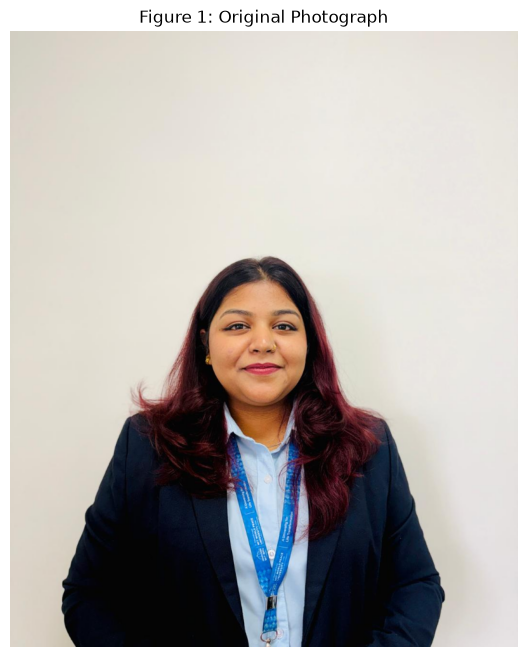

Image shape: (971, 800, 3)


In [2]:
# Load the original photograph
img = cv2.imread("data/original.jpg")

# Resize to 800 px width, keeping the aspect ratio
img = cv2.resize(img, (800, int(800 * img.shape[0] / img.shape[1])))

# Grayscale copy for later tasks
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

# Display
plt.figure(figsize=(8, 8))
plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.title("Figure 1: Original Photograph")
plt.axis("off")
plt.show()

print("Image shape:", img.shape)

**Observation:** The original photograph was loaded successfully. The image is sharp and well lit, with a strong contrast between the dark blazer and the light background. This makes it suitable for thresholding, edge detection and feature extraction in the later tasks.

# 2. Task 1: Image Restoration and Segmentation

## 2.1 Image Restoration

### 2.1.1 Adding Noise
To test restoration techniques, artificial noise is added to the clean grayscale image. Two types of noise are used:

- **Gaussian noise:** a random value from a normal distribution (mean 0, standard deviation 25) is added to every pixel. It looks like fine grain and affects all pixels slightly.
- **Salt-and-pepper noise:** a small percentage of pixels (5% here) is randomly set to pure black (0) or pure white (255). It affects only some pixels, but affects them strongly.

The clean grayscale image is kept as the **reference** for calculating PSNR and SSIM later.

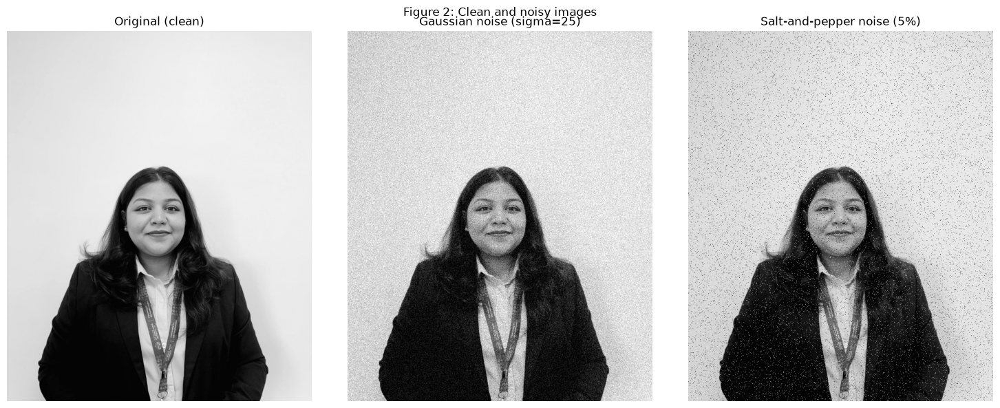

In [3]:
np.random.seed(42)   # fixed seed so the results are reproducible

# Gaussian noise
gaussian_noise = np.random.normal(0, 25, gray.shape)
noisy_gauss = np.clip(gray.astype(np.float64) + gaussian_noise, 0, 255).astype(np.uint8)

# Salt-and-pepper noise
noisy_sp = gray.copy()
rand = np.random.rand(*gray.shape)
noisy_sp[rand < 0.025] = 0       # pepper (2.5%)
noisy_sp[rand > 0.975] = 255     # salt (2.5%)

fig, ax = plt.subplots(1, 3, figsize=(15, 6))
ax[0].imshow(gray, cmap="gray");        ax[0].set_title("Original (clean)")
ax[1].imshow(noisy_gauss, cmap="gray"); ax[1].set_title("Gaussian noise (sigma=25)")
ax[2].imshow(noisy_sp, cmap="gray");    ax[2].set_title("Salt-and-pepper noise (5%)")
for a in ax: a.axis("off")
plt.suptitle("Figure 2: Clean and noisy images")
plt.tight_layout()
plt.savefig("outputs/fig2_noisy_images.png", dpi=150)
plt.show()

### 2.1.2 Restoring the Noisy Images
Two spatial filters are applied to both noisy images:

- **Median filter:** replaces each pixel with the median of the pixels in its neighbourhood (5x5 here). Extreme values such as pure black or white pixels are ignored, so it is expected to remove impulse noise well while keeping edges fairly sharp.
- **Gaussian filter:** replaces each pixel with a weighted average of its neighbourhood, where nearby pixels get higher weight (5x5 kernel, sigma = 1.2). It smooths random variations well but also blurs edges.

Both filters are applied to both noise types so that the four combinations can be compared.

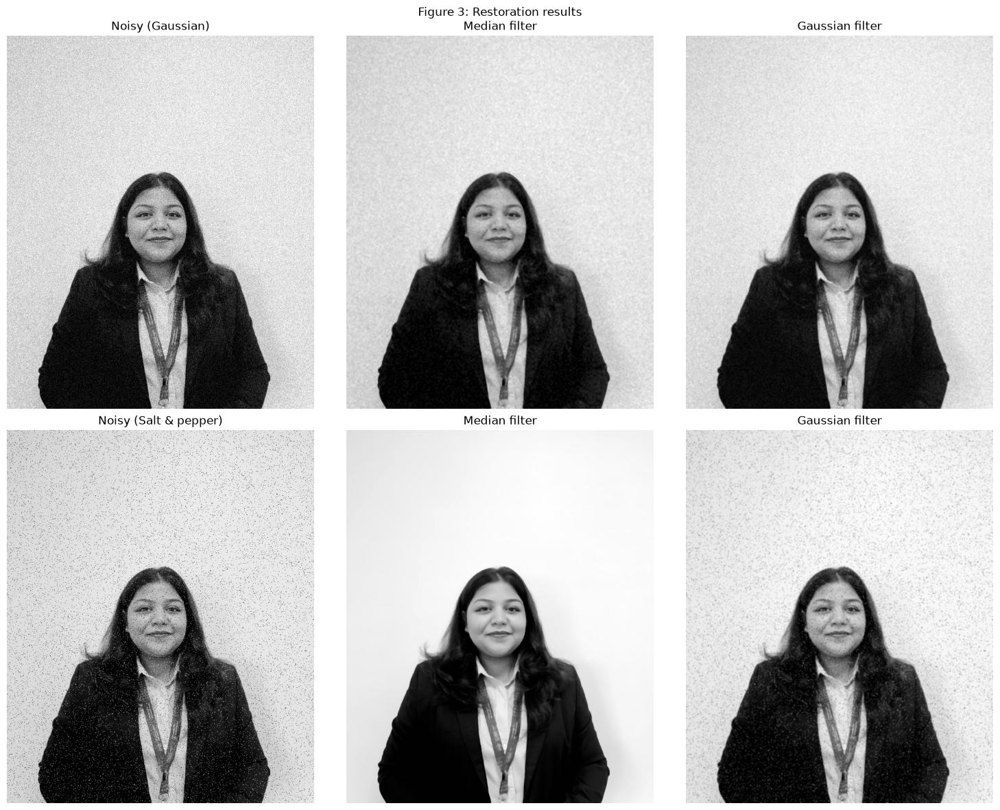

In [4]:
# Restoration of Gaussian-noise image
med_gauss = cv2.medianBlur(noisy_gauss, 5)
gau_gauss = cv2.GaussianBlur(noisy_gauss, (5, 5), 1.2)

# Restoration of salt-and-pepper image
med_sp = cv2.medianBlur(noisy_sp, 5)
gau_sp = cv2.GaussianBlur(noisy_sp, (5, 5), 1.2)

fig, ax = plt.subplots(2, 3, figsize=(15, 12))
ax[0,0].imshow(noisy_gauss, cmap="gray"); ax[0,0].set_title("Noisy (Gaussian)")
ax[0,1].imshow(med_gauss, cmap="gray");   ax[0,1].set_title("Median filter")
ax[0,2].imshow(gau_gauss, cmap="gray");   ax[0,2].set_title("Gaussian filter")
ax[1,0].imshow(noisy_sp, cmap="gray");    ax[1,0].set_title("Noisy (Salt & pepper)")
ax[1,1].imshow(med_sp, cmap="gray");      ax[1,1].set_title("Median filter")
ax[1,2].imshow(gau_sp, cmap="gray");      ax[1,2].set_title("Gaussian filter")
for a in ax.ravel(): a.axis("off")
plt.suptitle("Figure 3: Restoration results")
plt.tight_layout()
plt.savefig("outputs/fig3_restoration.png", dpi=150)
plt.show()

### 2.1.3 Quantitative Comparison (PSNR and SSIM)
The restored images are compared with the clean original using two measures:

- **PSNR (Peak Signal-to-Noise Ratio):** measured in dB. A higher value means the image is closer to the original.
- **SSIM (Structural Similarity Index):** ranges from 0 to 1. A value closer to 1 means the structure of the image is better preserved.

The noisy images are also measured, which gives a baseline to show whether each filter actually improved the image.

In [5]:
import pandas as pd

def evaluate(name, result):
    return {
        "Image": name,
        "PSNR (dB)": round(psnr(gray, result, data_range=255), 2),
        "SSIM": round(ssim(gray, result, data_range=255), 4),
    }

results = pd.DataFrame([
    evaluate("Gaussian noise (no filter)", noisy_gauss),
    evaluate("Gaussian noise + Median", med_gauss),
    evaluate("Gaussian noise + Gaussian filter", gau_gauss),
    evaluate("Salt & pepper (no filter)", noisy_sp),
    evaluate("Salt & pepper + Median", med_sp),
    evaluate("Salt & pepper + Gaussian filter", gau_sp),
])

results.to_csv("outputs/task1a_metrics.csv", index=False)
results


,Image,PSNR (dB),SSIM
0,Gaussian noise (no filter),21.19,0.1684
1,Gaussian noise + Median,30.74,0.6918
2,Gaussian noise + Gaussian filter,30.71,0.7093
3,Salt & pepper (no filter),16.99,0.2880
4,Salt & pepper + Median,37.06,0.9698
5,Salt & pepper + Gaussian filter,27.33,0.5748


**Table 1: Restoration metrics**
(The table above shows the PSNR and SSIM values for all six images.)

**Observations:**
- **Gaussian noise:** The noisy image had PSNR = 21.19 dB and SSIM = 0.1684. Both filters improved it by almost the same amount. The median filter gave PSNR = 30.74 dB and SSIM = 0.6918, while the Gaussian filter gave PSNR = 30.71 dB and SSIM = 0.7093. The PSNR values differ by only 0.03 dB, but the Gaussian filter has the higher SSIM, so it preserved the image structure slightly better.
- **Salt-and-pepper noise:** The noisy image had PSNR = 16.99 dB and SSIM = 0.2880. The median filter gave a very large improvement (PSNR = 37.06 dB, SSIM = 0.9698), while the Gaussian filter gave a much smaller improvement (PSNR = 27.33 dB, SSIM = 0.5748).
- **Visual check:** In Figure 3, the Gaussian filter result for salt-and-pepper noise still shows blurred dark and bright spots, because the extreme pixel values are averaged into their neighbours instead of being removed. The median filter output looks almost identical to the clean image.

**Comparison:** The difference between the two filters is very small for Gaussian noise (PSNR gap of 0.03 dB), but very large for salt-and-pepper noise (PSNR gap of about 9.7 dB and SSIM gap of about 0.39).

**Conclusion:** For my image, the **Gaussian filter** is marginally better for Gaussian noise (higher SSIM), although the median filter performs almost equally well. The **median filter** is clearly the best choice for salt-and-pepper noise. This is because the median filter ignores extreme values (pure black or white pixels) and replaces them with a typical neighbouring value, whereas the Gaussian filter averages the extreme values into the surrounding pixels, which spreads the noise instead of removing it. Gaussian noise affects every pixel by a small random amount, which an averaging filter can cancel out well. For Gaussian noise, both filters left some residual grain on the wall, but the Gaussian filter output looks slightly smoother.

## 2.2 Morphological Processing and Segmentation

### 2.2.1 Thresholding (Binary Image)
Thresholding converts a grayscale image into a binary image (only black and white). **Otsu's method** is used here: it automatically selects the threshold value that best separates the image into two classes (dark and bright pixels) by minimising the variance within each class.

In this photograph the dark blazer and hair contrast strongly with the light wall, so the person should appear as the white foreground after inverting the threshold. A small Gaussian blur is applied first so that the grain on the wall does not create isolated white dots.

Otsu threshold value: 122.0


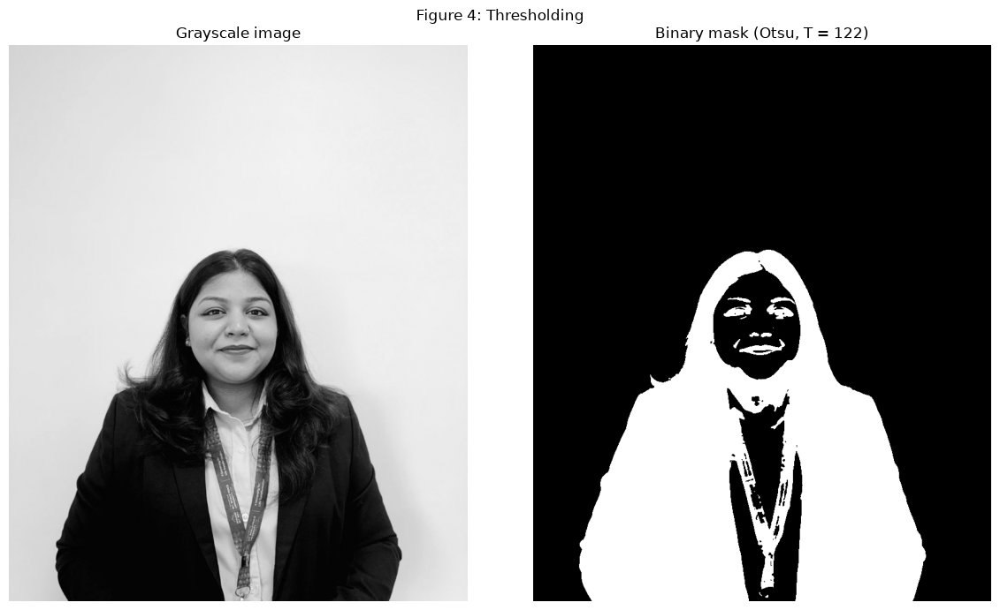

In [6]:
blur = cv2.GaussianBlur(gray, (5, 5), 0)

thresh_val, binary = cv2.threshold(blur, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)
print("Otsu threshold value:", thresh_val)

fig, ax = plt.subplots(1, 2, figsize=(12, 7))
ax[0].imshow(gray, cmap="gray");   ax[0].set_title("Grayscale image")
ax[1].imshow(binary, cmap="gray"); ax[1].set_title(f"Binary mask (Otsu, T = {thresh_val:.0f})")
for a in ax: a.axis("off")
plt.suptitle("Figure 4: Thresholding")
plt.tight_layout()
plt.savefig("outputs/fig4_threshold.png", dpi=150)
plt.show()

### 2.2.2 Morphological Operations
Morphological operations process the shape of white regions in a binary image using a small shape called a **structuring element** (a 5x5 square kernel here).

- **Erosion:** shrinks the white regions. Small white specks disappear and thin connections break.
- **Dilation:** expands the white regions. Small black holes and gaps are filled.
- **Opening (erosion followed by dilation):** removes small white noise while keeping the size of the main objects roughly the same.
- **Closing (dilation followed by erosion):** fills small black holes and gaps inside the white objects.

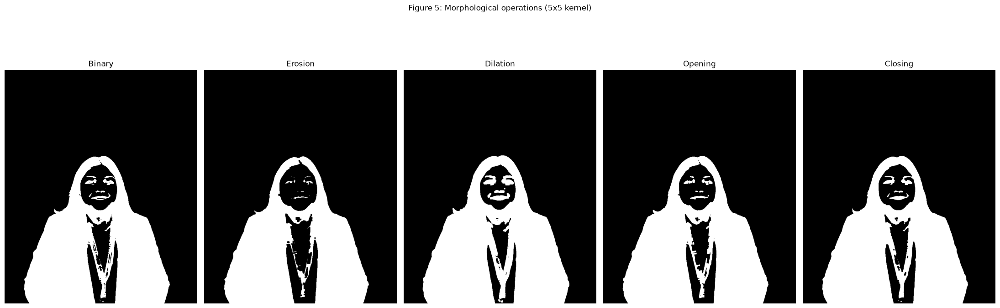

Binary     white pixels: 197905
Erosion    white pixels: 184302
Dilation   white pixels: 211110
Opening    white pixels: 196301
Closing    white pixels: 199214


In [7]:
kernel = np.ones((5, 5), np.uint8)

eroded  = cv2.erode(binary, kernel, iterations=1)
dilated = cv2.dilate(binary, kernel, iterations=1)
opened  = cv2.morphologyEx(binary, cv2.MORPH_OPEN,  kernel)
closed  = cv2.morphologyEx(binary, cv2.MORPH_CLOSE, kernel)

fig, ax = plt.subplots(1, 5, figsize=(22, 8))
imgs   = [binary, eroded, dilated, opened, closed]
titles = ["Binary", "Erosion", "Dilation", "Opening", "Closing"]
for a, im, t in zip(ax, imgs, titles):
    a.imshow(im, cmap="gray"); a.set_title(t); a.axis("off")
plt.suptitle("Figure 5: Morphological operations (5x5 kernel)")
plt.tight_layout()
plt.savefig("outputs/fig5_morphology.png", dpi=150)
plt.show()

# White pixel count shows how each operation changes the foreground
for name, im in zip(titles, imgs):
    print(f"{name:10s} white pixels: {np.count_nonzero(im)}")

### 2.2.3 Canny Edge Detection
The Canny detector finds thin, continuous edges in four steps: Gaussian smoothing, gradient calculation, non-maximum suppression (thinning the edges) and hysteresis thresholding. Hysteresis uses two thresholds: pixels with gradient above the **high** threshold are strong edges, pixels below the **low** threshold are discarded, and pixels in between are kept only if they connect to a strong edge.

Two threshold settings are compared to see how they affect the amount of detail.

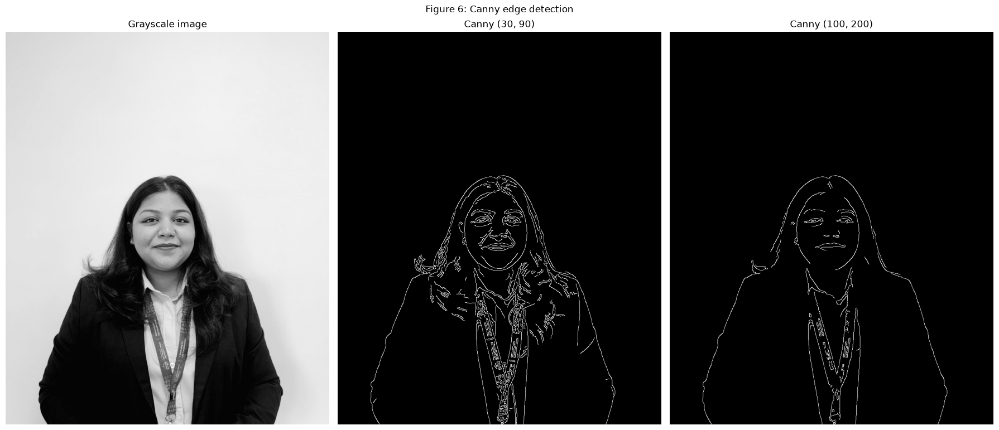

Edge pixels (30, 90):   14476
Edge pixels (100, 200): 6428


In [8]:
edges_low  = cv2.Canny(blur, 30, 90)     # sensitive: more edges
edges_high = cv2.Canny(blur, 100, 200)   # strict: fewer edges

fig, ax = plt.subplots(1, 3, figsize=(18, 8))
ax[0].imshow(gray, cmap="gray");       ax[0].set_title("Grayscale image")
ax[1].imshow(edges_low, cmap="gray");  ax[1].set_title("Canny (30, 90)")
ax[2].imshow(edges_high, cmap="gray"); ax[2].set_title("Canny (100, 200)")
for a in ax: a.axis("off")
plt.suptitle("Figure 6: Canny edge detection")
plt.tight_layout()
plt.savefig("outputs/fig6_canny.png", dpi=150)
plt.show()

print("Edge pixels (30, 90):  ", np.count_nonzero(edges_low))
print("Edge pixels (100, 200):", np.count_nonzero(edges_high))

### 2.2.4 Observations: Thresholding, Morphology and Canny

**Thresholding (Figure 4):** Otsu's method produced a clean binary mask in which the dark hair and blazer appear white (foreground) and the bright wall appears black. The face and the light blue shirt are brighter than the threshold, so they appear as black regions inside the person's silhouette. This shows that a single global threshold separates the person from the wall well, but it cannot separate the face from the wall, because both are bright.

**Morphological operations (Figure 5):**

| Operation | White pixels | Change from binary mask |
|---|---|---|
| Binary mask | 197,905 | - |
| Erosion | 184,302 | -13,603 (-6.9%) |
| Dilation | 211,110 | +13,205 (+6.7%) |
| Opening | 196,301 | -1,604 (-0.8%) |
| Closing | 199,214 | +1,309 (+0.7%) |

- Erosion and dilation change the foreground area by about 7% each, because they shrink or grow every boundary of the person by 2 pixels.
- Opening and closing change the area by less than 1%. They only remove or fill small isolated regions (small white specks and small black holes) and leave the main silhouette almost unchanged.
- For this image, **opening** is the most useful clean-up step because it removes small white specks without shrinking the person, and **closing** is useful for filling small gaps inside the blazer region.

**Canny edge detection (Figure 6):**
- With thresholds (30, 90) the detector found **14,476** edge pixels, and with (100, 200) it found **6,428** edge pixels, which is about 2.3 times fewer.
- The lower thresholds capture fine details such as individual hair strands, facial features, the collar and the lanyard text, but they also pick up more weak edges from the textured background.
- The higher thresholds keep only the strong outlines (the body shape, the face outline, the lanyard), and the edges are cleaner but some hair and facial detail is lost.

**Conclusion:** Otsu thresholding works well for this photograph because of the strong contrast between the dark clothing and the light wall. Opening gives the cleanest mask with the smallest change in area, and the Canny thresholds should be chosen according to the need: (30, 90) for detailed edges and (100, 200) for a clean outline.

### 2.2.5 Watershed Segmentation
Watershed treats a grayscale image like a landscape, where bright areas are hills and dark areas are valleys. Water "floods" the valleys from marker points, and a boundary (dam) is built wherever the water from two different markers would meet. This makes it suitable for separating **touching objects**, which simple thresholding would merge into one blob.

A separate photograph of rice grains (`objects.jpg`) is used because the portrait does not contain touching objects. The steps are:
1. Convert to grayscale, blur and apply Otsu thresholding to get a binary mask.
2. Apply opening to remove small noise.
3. **Sure background:** dilate the mask.
4. **Sure foreground:** apply the distance transform (distance of every white pixel from the nearest black pixel) and threshold it, so only the centres of grains remain.
5. **Unknown region:** sure background minus sure foreground.
6. Label each sure-foreground blob as a marker and run `cv2.watershed`. Boundaries are marked with -1.

Number of segments found: 80
Connected blobs before watershed: 19


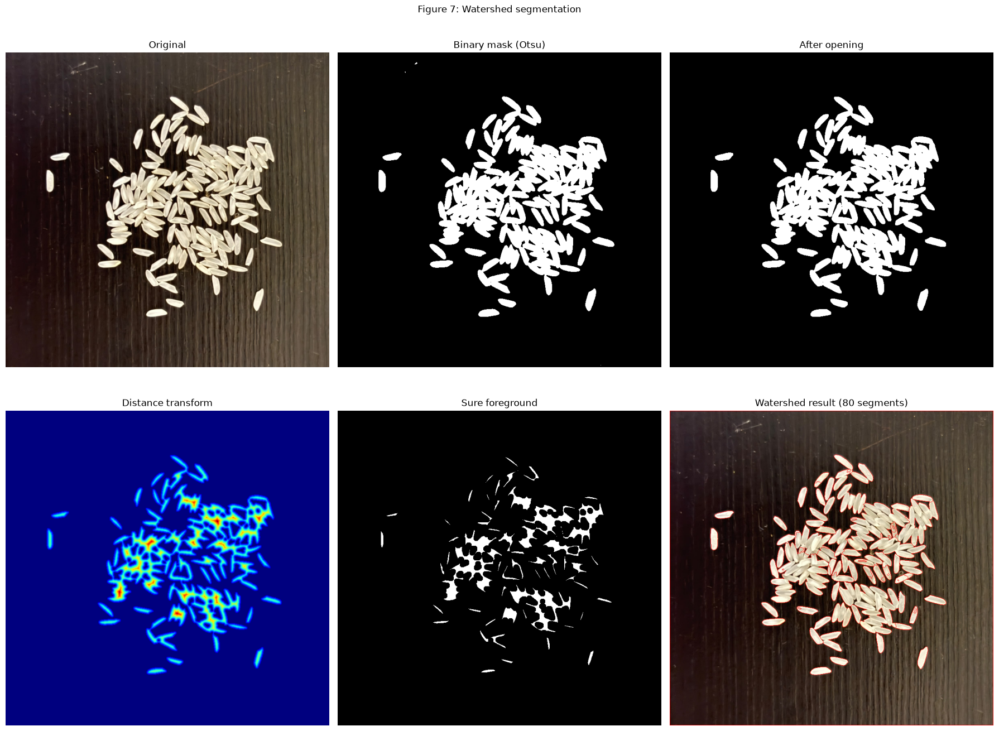

In [9]:
obj = cv2.imread("data/objects.jpg")
obj = cv2.resize(obj, (800, int(800 * obj.shape[0] / obj.shape[1])))
obj_gray = cv2.cvtColor(obj, cv2.COLOR_BGR2GRAY)
obj_blur = cv2.GaussianBlur(obj_gray, (5, 5), 0)

# Otsu threshold: make objects white regardless of background brightness
_, mask = cv2.threshold(obj_blur, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
border = np.concatenate([mask[0], mask[-1], mask[:, 0], mask[:, -1]])
if border.mean() > 127:                  # background came out white -> invert
    mask = cv2.bitwise_not(mask)

kernel = np.ones((3, 3), np.uint8)
opening = cv2.morphologyEx(mask, cv2.MORPH_OPEN, kernel, iterations=2)

sure_bg = cv2.dilate(opening, kernel, iterations=3)

dist = cv2.distanceTransform(opening, cv2.DIST_L2, 5)
FG_RATIO = 0.35        # tune this: lower -> fewer splits, higher -> more splits
_, sure_fg = cv2.threshold(dist, FG_RATIO * dist.max(), 255, 0)
sure_fg = sure_fg.astype(np.uint8)

unknown = cv2.subtract(sure_bg, sure_fg)

num_labels, markers = cv2.connectedComponents(sure_fg)
markers = markers + 1            # background becomes 1, objects 2, 3, ...
markers[unknown == 255] = 0      # unknown region = 0

markers = cv2.watershed(obj, markers)

result = obj.copy()
result[markers == -1] = [0, 0, 255]      # red boundaries
n_objects = len(np.unique(markers)) - 2  # remove background (1) and boundary (-1)
print("Number of segments found:", n_objects)
print("Connected blobs before watershed:", cv2.connectedComponents(opening)[0] - 1)

fig, ax = plt.subplots(2, 3, figsize=(18, 14))
ax[0,0].imshow(cv2.cvtColor(obj, cv2.COLOR_BGR2RGB)); ax[0,0].set_title("Original")
ax[0,1].imshow(mask, cmap="gray");                    ax[0,1].set_title("Binary mask (Otsu)")
ax[0,2].imshow(opening, cmap="gray");                 ax[0,2].set_title("After opening")
ax[1,0].imshow(dist, cmap="jet");                     ax[1,0].set_title("Distance transform")
ax[1,1].imshow(sure_fg, cmap="gray");                 ax[1,1].set_title("Sure foreground")
ax[1,2].imshow(cv2.cvtColor(result, cv2.COLOR_BGR2RGB)); ax[1,2].set_title(f"Watershed result ({n_objects} segments)")
for a in ax.ravel(): a.axis("off")
plt.suptitle("Figure 7: Watershed segmentation")
plt.tight_layout()
plt.savefig("outputs/fig7_watershed.png", dpi=150)
plt.show()

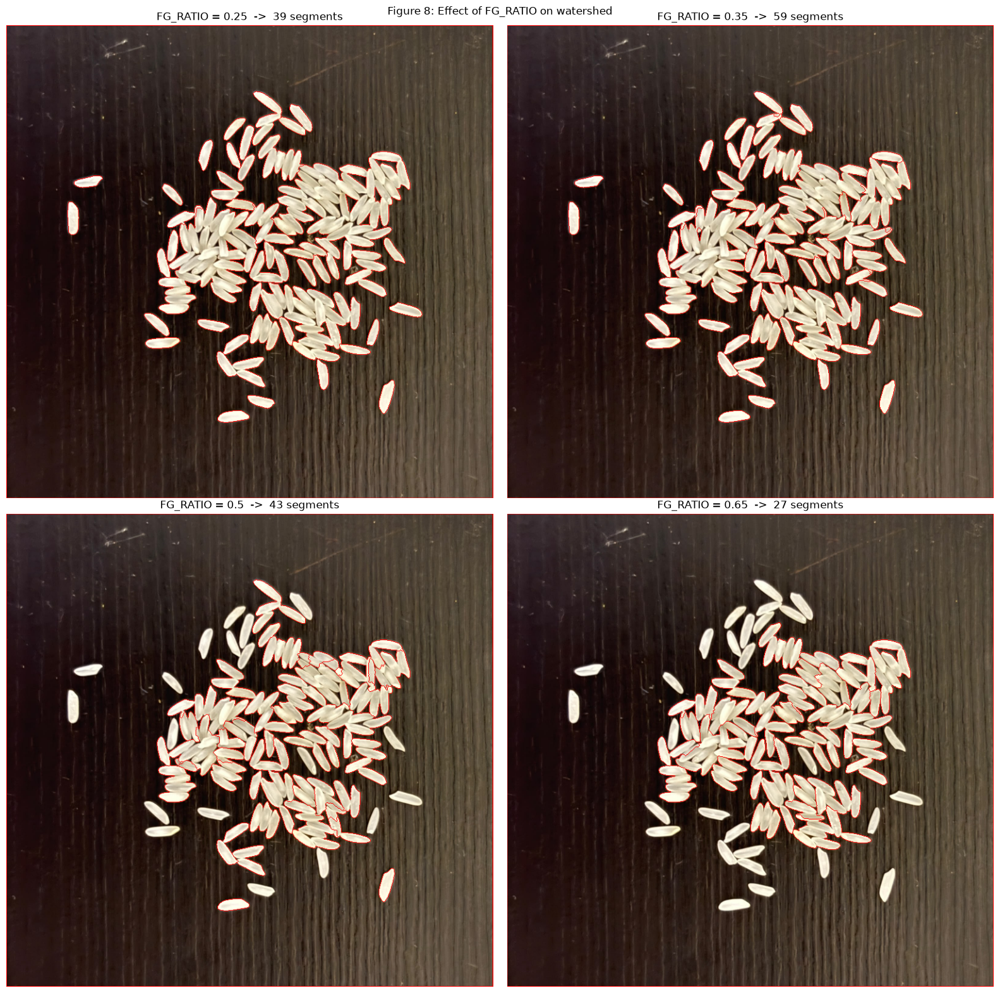

,FG_RATIO,Segments
0,0.25,39
1,0.35,59
2,0.50,43
3,0.65,27


In [10]:
def run_watershed(ratio, blur_k=3, open_iter=1):
    g = cv2.GaussianBlur(obj_gray, (blur_k, blur_k), 0)
    _, m = cv2.threshold(g, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    b = np.concatenate([m[0], m[-1], m[:, 0], m[:, -1]])
    if b.mean() > 127:
        m = cv2.bitwise_not(m)
    k = np.ones((3, 3), np.uint8)
    op = cv2.morphologyEx(m, cv2.MORPH_OPEN, k, iterations=open_iter)
    sbg = cv2.dilate(op, k, iterations=3)
    d = cv2.distanceTransform(op, cv2.DIST_L2, 5)
    _, sfg = cv2.threshold(d, ratio * d.max(), 255, 0)
    sfg = sfg.astype(np.uint8)
    unk = cv2.subtract(sbg, sfg)
    _, mk = cv2.connectedComponents(sfg)
    mk = mk + 1
    mk[unk == 255] = 0
    mk = cv2.watershed(obj.copy(), mk)
    out = obj.copy()
    out[mk == -1] = [0, 0, 255]
    return out, len(np.unique(mk)) - 2

ratios = [0.25, 0.35, 0.50, 0.65]
fig, ax = plt.subplots(2, 2, figsize=(16, 16))
tuning = []
for a, r in zip(ax.ravel(), ratios):
    out, n = run_watershed(r)
    tuning.append({"FG_RATIO": r, "Segments": n})
    a.imshow(cv2.cvtColor(out, cv2.COLOR_BGR2RGB))
    a.set_title(f"FG_RATIO = {r}  ->  {n} segments")
    a.axis("off")
plt.suptitle("Figure 8: Effect of FG_RATIO on watershed")
plt.tight_layout()
plt.savefig("outputs/fig8_watershed_tuning.png", dpi=150)
plt.show()

pd.DataFrame(tuning)

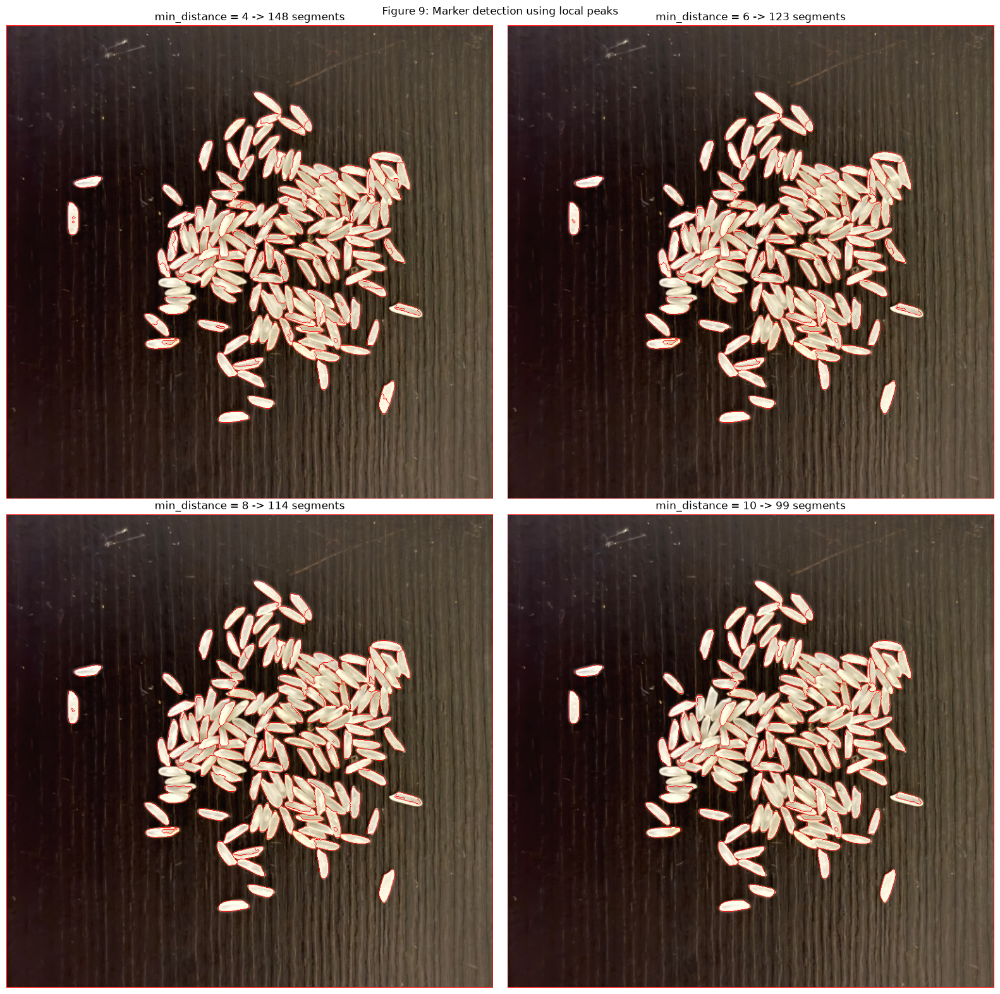

,min_distance,Segments
0,4,148
1,6,123
2,8,114
3,10,99


In [11]:
from skimage.feature import peak_local_max
from scipy import ndimage as ndi

def run_peaks(min_dist, sigma=1.5):
    g = cv2.GaussianBlur(obj_gray, (5, 5), 0)
    _, m = cv2.threshold(g, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    b = np.concatenate([m[0], m[-1], m[:, 0], m[:, -1]])
    if b.mean() > 127:
        m = cv2.bitwise_not(m)
    k = np.ones((3, 3), np.uint8)
    op = cv2.morphologyEx(m, cv2.MORPH_OPEN, k, iterations=2)

    d = cv2.distanceTransform(op, cv2.DIST_L2, 5)
    d_s = ndi.gaussian_filter(d, sigma)
    pts = peak_local_max(d_s, min_distance=min_dist, threshold_abs=2,
                         labels=(op > 0).astype(int))

    mk = np.zeros(d.shape, np.int32)
    mk[op == 0] = 1                                   # background marker
    for i, (r, c) in enumerate(pts, start=2):         # one marker per peak
        mk[r, c] = i
    mk = cv2.watershed(obj.copy(), mk)

    out = obj.copy()
    out[mk == -1] = [0, 0, 255]
    return out, len(pts)

dists = [4, 6, 8, 10]
fig, ax = plt.subplots(2, 2, figsize=(16, 16))
peak_table = []
for a, md in zip(ax.ravel(), dists):
    out, n = run_peaks(md)
    peak_table.append({"min_distance": md, "Segments": n})
    a.imshow(cv2.cvtColor(out, cv2.COLOR_BGR2RGB))
    a.set_title(f"min_distance = {md} -> {n} segments")
    a.axis("off")
plt.suptitle("Figure 9: Marker detection using local peaks")
plt.tight_layout()
plt.savefig("outputs/fig9_watershed_peaks.png", dpi=150)
plt.show()

pd.DataFrame(peak_table)

### 2.2.6 Watershed Observations

**Setup:** The photograph of rice grains on a dark table (`objects.jpg`) was used, because the grains touch and overlap each other, and simple thresholding merges them into large blobs.

**Method 1: global threshold on the distance transform (Figures 7 and 8).** After thresholding and opening, the mask contained only **19 connected blobs**. Watershed with FG_RATIO = 0.35 split these into **80 segments**. When the pre-processing was reduced (3x3 blur, 1 opening iteration), the count changed unevenly with the ratio:

| FG_RATIO | Segments |
|---|---|
| 0.25 | 39 |
| 0.35 | 59 |
| 0.50 | 43 |
| 0.65 | 27 |

A higher ratio removes the markers of smaller or thinner grains, because their distance-transform peaks fall below the threshold. Those grains are then merged with their neighbours or are not segmented at all, as seen for the isolated grains at FG_RATIO = 0.5 and 0.65. A single global threshold is therefore not ideal when grains differ in size and orientation.

**Method 2: one marker per local peak (Figure 9).** Instead of a global threshold, every local maximum of the smoothed distance transform was used as a marker.

| min_distance (pixels) | Segments |
|---|---|
| 4 | 148 |
| 6 | 123 |
| 8 | 114 |
| 10 | 99 |

The count decreases steadily as min_distance increases, because nearby peaks are merged into one marker. A small value (4) tends to split a single long grain into several parts, while a large value (10) merges neighbouring grains. I selected **min_distance = 6** as a balance (123 segments), after checking the result visually.

**Comparison:** The local-peak method separated far more grains (up to 148) than the global-threshold method (maximum 80), because small and thin grains also get their own marker.

**Limitations:** In the dense centre of the pile, grains lie on top of each other. Watershed works in 2D and cannot see this depth, so some grains there are still merged or split incorrectly. The number of segments is the number of markers and was judged visually, as there is no ground-truth count.

**Conclusion:** Watershed separates touching objects much better than thresholding alone (19 blobs -> 123-148 segments), but the result depends strongly on how the markers are chosen.

### 2.3 Task 1 Summary

| Step | Technique | Best choice for my images |
|---|---|---|
| Restoration (Gaussian noise) | Median vs Gaussian filter | Gaussian filter (marginally; PSNR 30.71 dB, SSIM 0.7093) |
| Restoration (salt-and-pepper noise) | Median vs Gaussian filter | Median filter (PSNR 37.06 dB, SSIM 0.9698) |
| Binary mask | Otsu thresholding | Works well for the dark clothing against the light wall (T = 122) |
| Morphology | Erosion, dilation, opening, closing | Opening gave the cleanest mask with the smallest area change (-0.8%) |
| Edges | Canny | (30, 90) for detail, (100, 200) for a clean outline |
| Touching objects | Watershed | Local-peak markers (min_distance = 6) gave 123 segments from 19 merged blobs; a global threshold gave at most 80 |

# 3. Task 2: Feature Extraction and Image Matching

## 3.1 Histogram of Oriented Gradients (HOG)
HOG describes the shape of objects using the **direction of edges**. The image is divided into small cells (8x8 pixels here), and for each cell a histogram of gradient directions (9 bins) is calculated. Cells are then grouped into overlapping blocks (2x2 cells) and normalised, so that the descriptor is less affected by lighting changes. The final feature vector is the concatenation of all block histograms.

In the visualisation, each cell shows small lines whose length is proportional to the strength of edges in that direction. Strong outlines appear as bright lines.

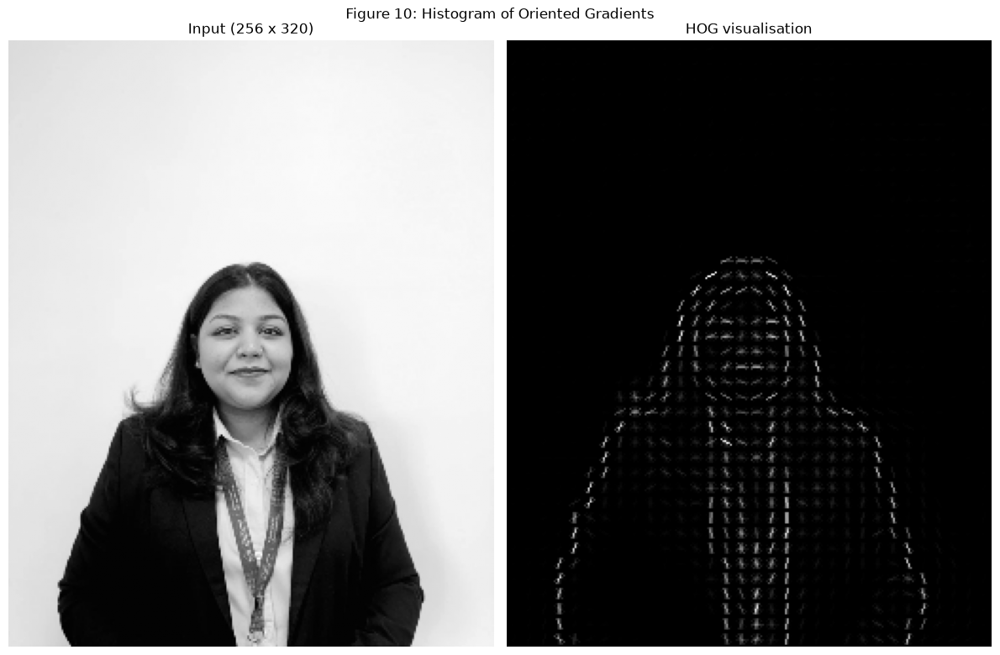

HOG feature vector length: 43524


In [12]:
from skimage.feature import hog
from skimage import exposure
import pandas as pd

hog_input = cv2.resize(gray, (256, 320))   # fixed size so the feature length is known

features, hog_image = hog(
    hog_input,
    orientations=9,
    pixels_per_cell=(8, 8),
    cells_per_block=(2, 2),
    block_norm="L2-Hys",
    visualize=True,
)
hog_image = exposure.rescale_intensity(hog_image, in_range=(0, hog_image.max()))

fig, ax = plt.subplots(1, 2, figsize=(12, 8))
ax[0].imshow(hog_input, cmap="gray"); ax[0].set_title("Input (256 x 320)")
ax[1].imshow(hog_image, cmap="gray"); ax[1].set_title("HOG visualisation")
for a in ax: a.axis("off")
plt.suptitle("Figure 10: Histogram of Oriented Gradients")
plt.tight_layout()
plt.savefig("outputs/fig10_hog.png", dpi=150)
plt.show()

print("HOG feature vector length:", features.shape[0])

## 3.2 SIFT Keypoints and Descriptors
SIFT (Scale-Invariant Feature Transform) finds **keypoints**, which are distinctive points such as corners and blobs that can be found again even if the image is scaled or rotated. For each keypoint it computes a **128-dimensional descriptor** that describes the gradients around the point. In the figures, the size of each circle shows the scale of the keypoint and the line inside shows its orientation.

The second photograph of the same scene (`second1.jpg`) is loaded and resized to the same width as the original.

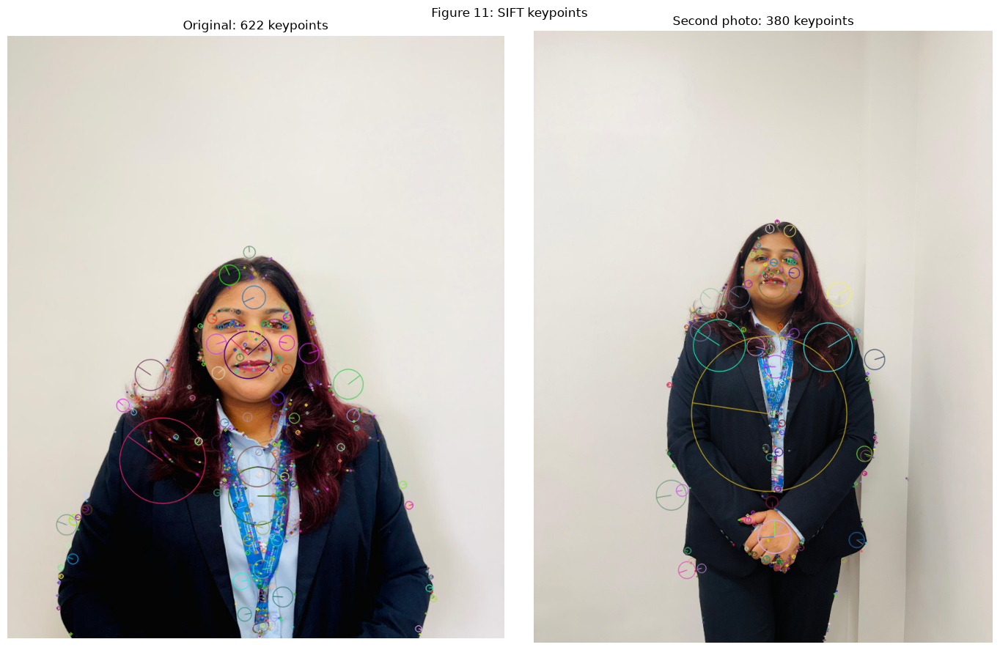

Descriptor shape (original): (622, 128)


In [13]:
def load_resized(path, width=800):
    im = cv2.imread(path)
    if im is None:
        raise FileNotFoundError(f"Could not read {path}")
    return cv2.resize(im, (width, int(width * im.shape[0] / im.shape[1])))

img2 = load_resized("data/second1.jpg")
gray2 = cv2.cvtColor(img2, cv2.COLOR_BGR2GRAY)

sift = cv2.SIFT_create()
kp1, des1 = sift.detectAndCompute(gray, None)
kp2, des2 = sift.detectAndCompute(gray2, None)

vis1 = cv2.drawKeypoints(img,  kp1, None, flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)
vis2 = cv2.drawKeypoints(img2, kp2, None, flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)

fig, ax = plt.subplots(1, 2, figsize=(14, 9))
ax[0].imshow(cv2.cvtColor(vis1, cv2.COLOR_BGR2RGB)); ax[0].set_title(f"Original: {len(kp1)} keypoints")
ax[1].imshow(cv2.cvtColor(vis2, cv2.COLOR_BGR2RGB)); ax[1].set_title(f"Second photo: {len(kp2)} keypoints")
for a in ax: a.axis("off")
plt.suptitle("Figure 11: SIFT keypoints")
plt.tight_layout()
plt.savefig("outputs/fig11_sift_keypoints.png", dpi=150)
plt.show()

print("Descriptor shape (original):", des1.shape)

### 3.2.1 Observations: HOG and SIFT Keypoints

**HOG (Figure 10):** The HOG feature vector has a length of **43,524** values for a 256 x 320 image (32 x 40 cells of 8x8 pixels, 31 x 39 overlapping blocks, 36 values per block). In the visualisation, the strongest gradients appear along the outline of the hair and shoulders, the edges of the blazer and the lanyard, and around the face. The plain wall gives almost no response and appears black, so HOG describes the **shape of the person** rather than the background.

**SIFT keypoints (Figure 11):** SIFT found **622 keypoints** in the original photograph and **380** in the second photograph. Most keypoints lie on the face, hair, lanyard and blazer edges, while very few lie on the plain wall, because a uniform region has no corners or blobs. Each keypoint has a 128-dimensional descriptor (descriptor matrix of shape 622 x 128). The second photograph has fewer keypoints because the person is smaller in the frame, so fewer pixels carry detail. The few very large circles in the second photograph are keypoints detected at a large scale, on the broad blazer region.

## 3.3 Feature Matching Between Two Images
To match the original photograph with the second photograph, each SIFT descriptor of image 1 is compared with all descriptors of image 2 using the Euclidean (L2) distance (brute-force matcher). For every descriptor the two nearest neighbours are found.

**Lowe's ratio test:** a match is accepted only if the best distance is less than 0.75 times the second-best distance. This removes ambiguous matches, where the descriptor looks similar to several points.

**RANSAC geometric check:** the accepted matches are fitted with a homography using RANSAC (reprojection error 5 px). Matches that agree with one common geometric transformation are called **inliers** and are drawn in green. A homography assumes a flat scene, so for a person who has moved between two photographs only the rigid parts (such as the ID card and the lanyard) are expected to agree, and the inlier count will be lower than the ratio-test count.

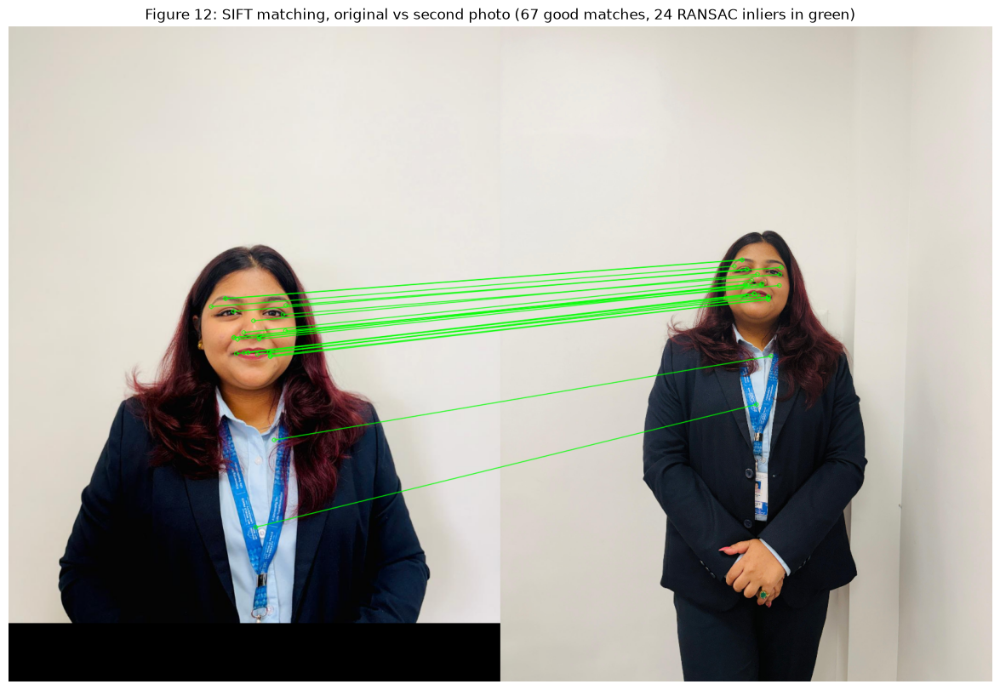

622 keypoints in image 1, 380 in image 2
Matches after ratio test: 67
RANSAC inliers:           24


In [14]:
bf = cv2.BFMatcher(cv2.NORM_L2)

def match_sift(imA, imB, ratio=0.75):
    gA = cv2.cvtColor(imA, cv2.COLOR_BGR2GRAY)
    gB = cv2.cvtColor(imB, cv2.COLOR_BGR2GRAY)
    kpA, dA = sift.detectAndCompute(gA, None)
    kpB, dB = sift.detectAndCompute(gB, None)
    knn = bf.knnMatch(dA, dB, k=2)
    good = [p[0] for p in knn if len(p) == 2 and p[0].distance < ratio * p[1].distance]

    inliers, mask = 0, None
    if len(good) >= 4:
        src = np.float32([kpA[m.queryIdx].pt for m in good]).reshape(-1, 1, 2)
        dst = np.float32([kpB[m.trainIdx].pt for m in good]).reshape(-1, 1, 2)
        H, mask = cv2.findHomography(src, dst, cv2.RANSAC, 5.0)
        inliers = int(mask.sum()) if mask is not None else 0

    vis = cv2.drawMatches(
        imA, kpA, imB, kpB, good, None,
        matchesMask=mask.ravel().tolist() if mask is not None else None,
        matchColor=(0, 255, 0),
        flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS,
    )
    return {"kpA": len(kpA), "kpB": len(kpB), "good": len(good), "inliers": inliers, "vis": vis}

r0 = match_sift(img, img2)

plt.figure(figsize=(16, 10))
plt.imshow(cv2.cvtColor(r0["vis"], cv2.COLOR_BGR2RGB))
plt.title(f"Figure 12: SIFT matching, original vs second photo "
          f"({r0['good']} good matches, {r0['inliers']} RANSAC inliers in green)")
plt.axis("off")
plt.savefig("outputs/fig12_sift_matching.png", dpi=150)
plt.show()

print(r0["kpA"], "keypoints in image 1,", r0["kpB"], "in image 2")
print("Matches after ratio test:", r0["good"])
print("RANSAC inliers:          ", r0["inliers"])

## 3.4 Matching After Rotating or Resizing One Image
SIFT is designed to be invariant to scale and rotation, so the matching is repeated after transforming the **second photograph**:

1. rotated by 45 degrees (the canvas is enlarged so that nothing is cut off),
2. rotated by 90 degrees,
3. resized to 50% of its size,
4. rotated by 45 degrees **and** resized to 50%.

For every case the number of keypoints, the matches after the ratio test and the RANSAC inliers are recorded, so the matching quality can be compared with the unmodified case.

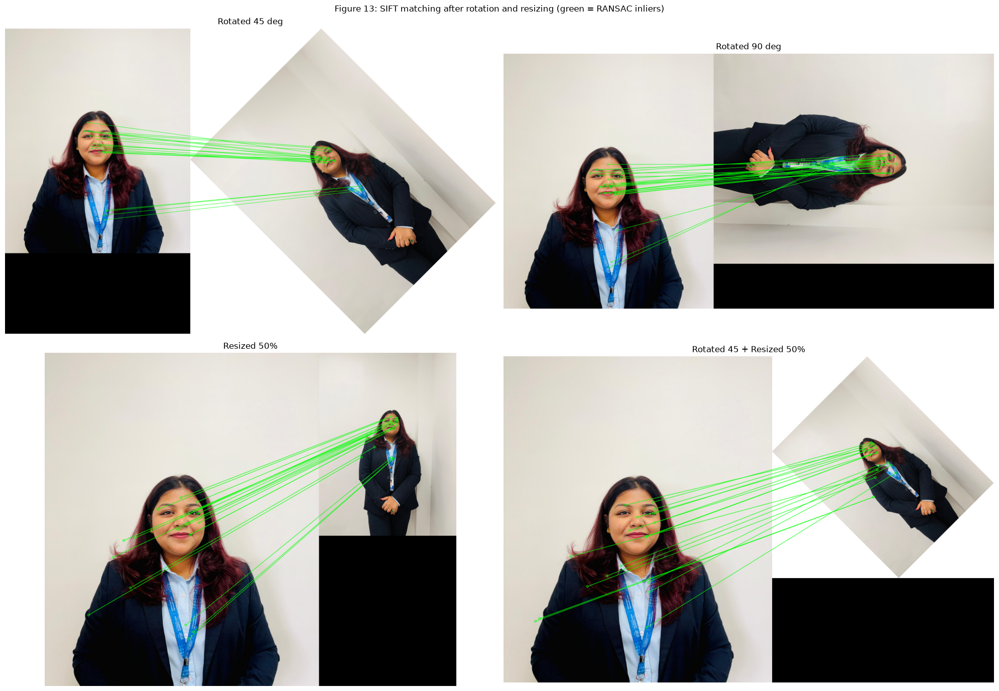

,Second image,Keypoints (image 2),Matches (ratio test),RANSAC inliers
0,Unmodified,380,67,24
1,Rotated 45 deg,468,59,22
2,Rotated 90 deg,378,68,26
3,Resized 50%,165,51,19
4,Rotated 45 + Resized 50%,194,48,18


In [15]:
def rotate_bound(im, angle):
    h, w = im.shape[:2]
    M = cv2.getRotationMatrix2D((w / 2, h / 2), angle, 1.0)
    cos, sin = abs(M[0, 0]), abs(M[0, 1])
    nw, nh = int(h * sin + w * cos), int(h * cos + w * sin)
    M[0, 2] += nw / 2 - w / 2
    M[1, 2] += nh / 2 - h / 2
    return cv2.warpAffine(im, M, (nw, nh), borderValue=(255, 255, 255))

half = lambda im: cv2.resize(im, None, fx=0.5, fy=0.5, interpolation=cv2.INTER_AREA)

variants = {
    "Unmodified":               img2,
    "Rotated 45 deg":           rotate_bound(img2, 45),
    "Rotated 90 deg":           cv2.rotate(img2, cv2.ROTATE_90_CLOCKWISE),
    "Resized 50%":              half(img2),
    "Rotated 45 + Resized 50%": half(rotate_bound(img2, 45)),
}

rows, visuals = [], {}
for name, im in variants.items():
    r = match_sift(img, im)
    visuals[name] = r["vis"]
    rows.append({
        "Second image": name,
        "Keypoints (image 2)": r["kpB"],
        "Matches (ratio test)": r["good"],
        "RANSAC inliers": r["inliers"],
    })

table2 = pd.DataFrame(rows)
table2.to_csv("outputs/task2_matching.csv", index=False)

fig, ax = plt.subplots(2, 2, figsize=(20, 14))
for a, name in zip(ax.ravel(), list(variants)[1:]):
    a.imshow(cv2.cvtColor(visuals[name], cv2.COLOR_BGR2RGB))
    a.set_title(name)
    a.axis("off")
plt.suptitle("Figure 13: SIFT matching after rotation and resizing (green = RANSAC inliers)")
plt.tight_layout()
plt.savefig("outputs/fig13_sift_transformed.png", dpi=120)
plt.show()

table2

### 3.4.1 Comparison of Matching Quality

**Table 2: SIFT matching results** (the table above shows keypoints, ratio-test matches and RANSAC inliers for each case)

| Second image | Keypoints | Matches (ratio test) | RANSAC inliers | Inliers / matches |
|---|---|---|---|---|
| Unmodified | 380 | 67 | 24 | 36% |
| Rotated 45 deg | 468 | 59 | 22 | 37% |
| Rotated 90 deg | 378 | 68 | 26 | 38% |
| Resized 50% | 165 | 51 | 19 | 37% |
| Rotated 45 + Resized 50% | 194 | 48 | 18 | 38% |

**Observations:**
- For the **unmodified** second photograph there were **67 good matches and 24 inliers**. Even this pair is not trivial: the person stands farther from the camera in the second photograph, so the scale, pose and framing differ. The inliers are concentrated on the **face (eyes, nose, mouth)**, with two on the lanyard (Figure 12).
- **Rotation by 90 degrees** gave 68 matches and 26 inliers, practically the same as the unmodified case. A 90-degree rotation only rearranges pixels without interpolation, so the local patterns are unchanged and SIFT's orientation assignment handles it fully.
- **Rotation by 45 degrees** reduced the matches slightly, to 59 (-12%), and inliers to 22. The keypoint count rose to 468 because the white borders and diagonal edges created by the rotation add extra keypoints that have no partner in the first image. The image is also resampled, which slightly changes pixel patterns.
- **Resizing to 50%** had the larger effect: keypoints dropped from 380 to 165 (-57%) and matches to 51 (-24%), with 19 inliers. Fine details disappear at lower resolution, so fewer keypoints survive.
- **Rotation and resizing together** was the hardest case: 48 matches and 18 inliers, the lowest in the table.
- The ratio of inliers to matches stayed at **36-38%** in all cases, which means the quality of the
- **Wrong matches (Figure 14):** Of the 67 matches that passed the ratio test, 24 were inliers (green) and **43 were rejected by RANSAC (red)**. The correct matches lie almost entirely on the **face** (eyes, nose, mouth) and a few on the lanyard. The rejected matches are mostly on the **hair, blazer and shoulders**, and many of them cross each other and connect to unrelated parts of the second photograph. These regions have repeated, similar-looking texture (hair strands and dark fabric), so their local descriptors look alike even though they are different points, and the ratio test alone cannot remove all of them. Figures 12 and 13 show only the inliers, so the wrong matches are visible only in Figure 14.

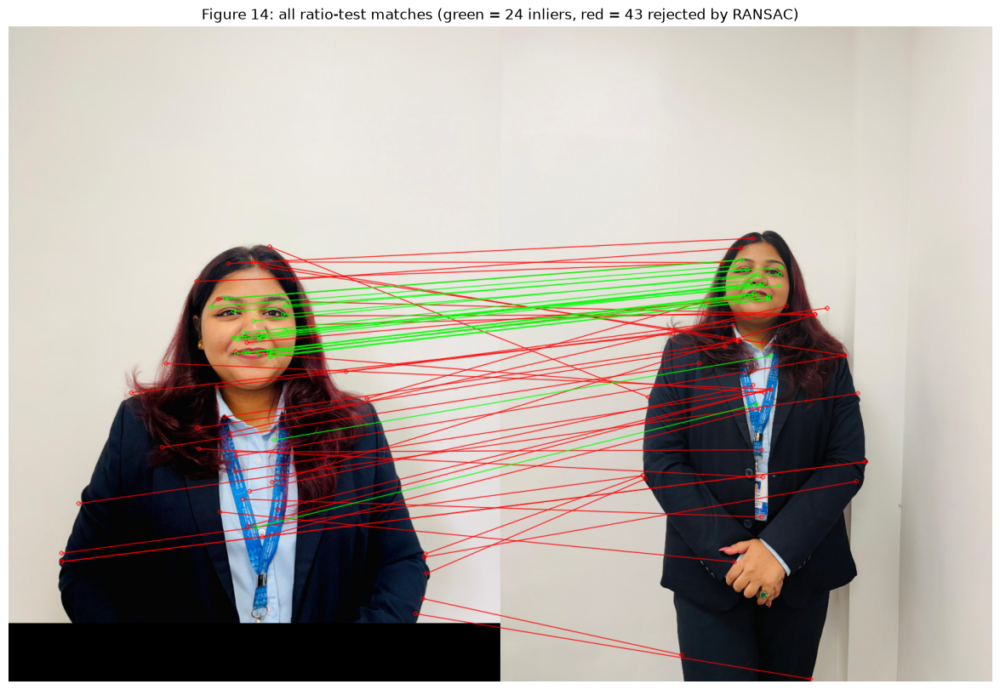

In [16]:
def draw_all_matches(imA, imB, ratio=0.75):
    gA = cv2.cvtColor(imA, cv2.COLOR_BGR2GRAY)
    gB = cv2.cvtColor(imB, cv2.COLOR_BGR2GRAY)
    kpA, dA = sift.detectAndCompute(gA, None)
    kpB, dB = sift.detectAndCompute(gB, None)
    knn = bf.knnMatch(dA, dB, k=2)
    good = [p[0] for p in knn if len(p) == 2 and p[0].distance < ratio * p[1].distance]

    src = np.float32([kpA[m.queryIdx].pt for m in good]).reshape(-1, 1, 2)
    dst = np.float32([kpB[m.trainIdx].pt for m in good]).reshape(-1, 1, 2)
    H, mask = cv2.findHomography(src, dst, cv2.RANSAC, 5.0)
    keep = mask.ravel().astype(bool)
    inl = [g for g, k in zip(good, keep) if k]
    rej = [g for g, k in zip(good, keep) if not k]

    vis = cv2.drawMatches(imA, kpA, imB, kpB, rej, None, matchColor=(0, 0, 255),
                          flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS)
    vis = cv2.drawMatches(imA, kpA, imB, kpB, inl, vis, matchColor=(0, 255, 0),
                          flags=cv2.DrawMatchesFlags_DRAW_OVER_OUTIMG |
                                cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS)
    return vis, len(inl), len(rej)

vis_all, n_in, n_rej = draw_all_matches(img, img2)
plt.figure(figsize=(16, 10))
plt.imshow(cv2.cvtColor(vis_all, cv2.COLOR_BGR2RGB))
plt.title(f"Figure 14: all ratio-test matches (green = {n_in} inliers, red = {n_rej} rejected by RANSAC)")
plt.axis("off")
plt.savefig("outputs/fig14_all_matches.png", dpi=150)
plt.show()

### 3.5 Task 2 Summary

| Step | Technique | Result on my images |
|---|---|---|
| Shape descriptor | HOG (8x8 cells, 9 bins) | 43,524 features; strongest on the outline of hair, shoulders and lanyard |
| Keypoints | SIFT | 622 (original) and 380 (second photo), concentrated on face, hair and lanyard |
| Matching | Ratio test (0.75) + RANSAC | 67 matches, 24 inliers; 43 matches rejected as wrong (Figure 14) |
| Rotation | 45 and 90 degrees | 59 and 68 matches: nearly unaffected |
| Scaling | 50% resize | 51 matches (-24%), 19 inliers |
| Rotation + scaling | 45 degrees + 50% | 48 matches, 18 inliers (hardest case) |

In [17]:
from ultralytics import YOLO

# 4. Task 3: Object Recognition Using Viola-Jones and YOLO

## 4.1 Methods

**Viola-Jones (Haar cascade):** a classical detector. It slides a window over the image at several scales and computes simple rectangular **Haar features** (differences of brightness between adjacent rectangles, for example the eye region is darker than the cheeks). A cascade of **AdaBoost** classifiers rejects non-face windows early, which makes it fast. The pretrained `haarcascade_frontalface_default.xml` detects only **frontal faces**. It gives no class label or probability, so the cascade's level weight is reported as a score.

**YOLO (YOLOv8n):** a deep neural network that looks at the whole image once and predicts bounding boxes, class labels and **confidence scores** directly. The pretrained model was trained on the COCO dataset (80 classes, for example person, bottle, mouse, laptop, tie). A confidence threshold of 0.25 is used.

Both detectors are applied to my photographs and to frames from my video, and the results are compared.

Cascade loaded correctly: True


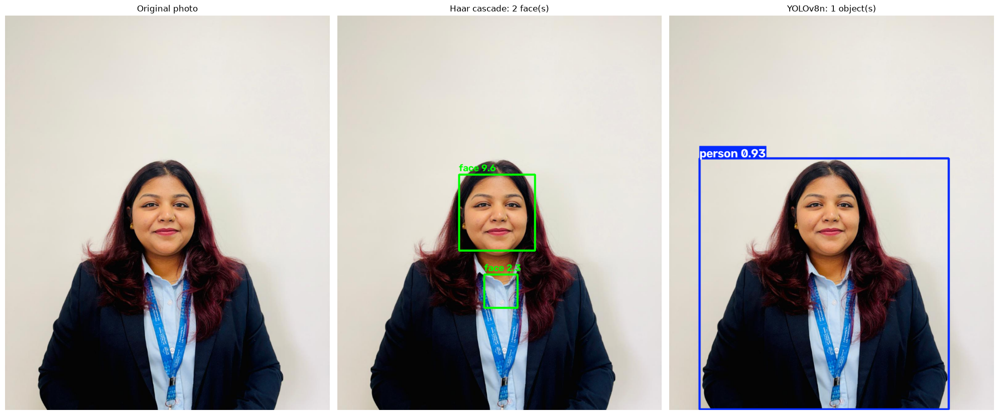

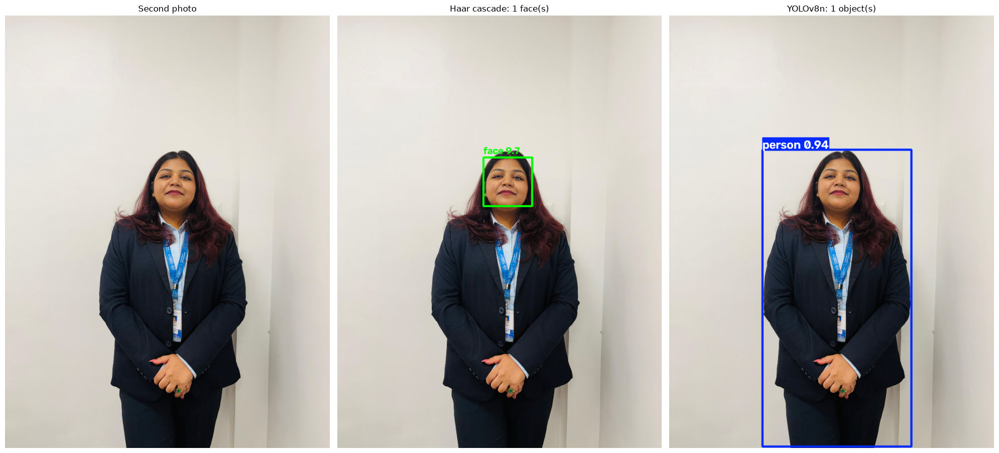

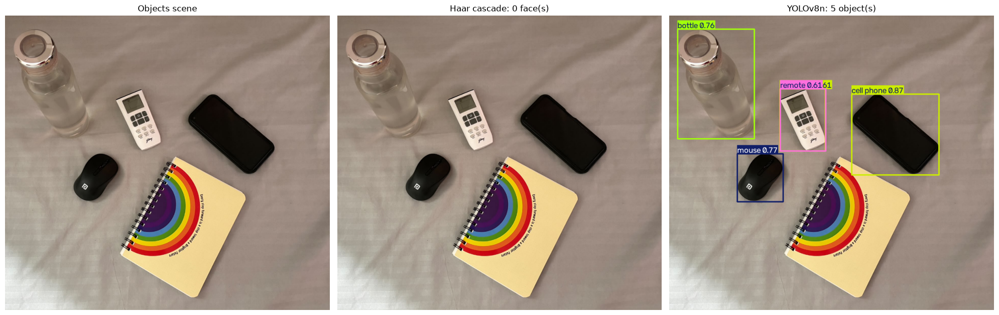

,Image,Haar faces,YOLO detections
0,Original photo,2,person (0.93)
1,Second photo,1,person (0.94)
2,Objects scene,0,"cell phone (0.87), mouse (0.77), bottle (0.76)..."


In [18]:
import os
from ultralytics import YOLO

import urllib.request

xml_path = "data/haarcascade_frontalface_default.xml"
if not os.path.exists(xml_path):
    url = ("https://raw.githubusercontent.com/opencv/opencv/4.x/"
           "data/haarcascades/haarcascade_frontalface_default.xml")
    urllib.request.urlretrieve(url, xml_path)
    print("Downloaded cascade file to", xml_path)

face_cascade = cv2.CascadeClassifier(xml_path)
print("Cascade loaded correctly:", not face_cascade.empty())
yolo = YOLO("yolov8n.pt")   # downloaded automatically the first time

# add video frames here later, e.g. "data/frame1.jpg"
candidates = {
    "Original photo":  "data/original.jpg",
    "Second photo":    "data/second1.jpg",
    "Objects scene":   "data/objects_scene.jpg",
}
test_imgs = {k: load_resized(v) for k, v in candidates.items() if os.path.exists(v)}

def run_haar(im):
    g = cv2.cvtColor(im, cv2.COLOR_BGR2GRAY)
    rects, _, weights = face_cascade.detectMultiScale3(
        g, scaleFactor=1.1, minNeighbors=5, minSize=(60, 60), outputRejectLevels=True)
    out = im.copy()
    for (x, y, w, h), s in zip(rects, np.ravel(weights)):
        cv2.rectangle(out, (x, y), (x + w, y + h), (0, 255, 0), 3)
        cv2.putText(out, f"face {s:.1f}", (x, y - 8), cv2.FONT_HERSHEY_SIMPLEX, 0.8, (0, 255, 0), 2)
    return out, len(rects)

def run_yolo(im, conf=0.25):
    r = yolo(im, conf=conf, verbose=False)[0]
    dets = [(yolo.names[int(b.cls)], float(b.conf)) for b in r.boxes]
    return r.plot(), dets

rows = []
for name, im in test_imgs.items():
    h_img, n_faces = run_haar(im)
    y_img, dets = run_yolo(im)

    fig, ax = plt.subplots(1, 3, figsize=(20, 9))
    ax[0].imshow(cv2.cvtColor(im, cv2.COLOR_BGR2RGB));    ax[0].set_title(name)
    ax[1].imshow(cv2.cvtColor(h_img, cv2.COLOR_BGR2RGB)); ax[1].set_title(f"Haar cascade: {n_faces} face(s)")
    ax[2].imshow(cv2.cvtColor(y_img, cv2.COLOR_BGR2RGB)); ax[2].set_title(f"YOLOv8n: {len(dets)} object(s)")
    for a in ax: a.axis("off")
    plt.tight_layout()
    plt.savefig(f"outputs/fig_detect_{name.replace(' ', '_')}.png", dpi=120)
    plt.show()

    rows.append({
        "Image": name,
        "Haar faces": n_faces,
        "YOLO detections": ", ".join(f"{c} ({p:.2f})" for c, p in dets) or "none",
    })

table3 = pd.DataFrame(rows)
table3.to_csv("outputs/task3_detections.csv", index=False)
table3

In [19]:
import time

im = test_imgs["Original photo"]
g = cv2.cvtColor(im, cv2.COLOR_BGR2GRAY)

# 1) exact boxes and scores for the default setting
rects, _, weights = face_cascade.detectMultiScale3(
    g, scaleFactor=1.1, minNeighbors=5, minSize=(60, 60), outputRejectLevels=True)
for (x, y, w, h), s in zip(rects, np.ravel(weights)):
    print(f"box x={x}, y={y}, size={w}x{h}, score={s:.2f}")

# 2) effect of minNeighbors on the number of detections
rows = []
for mn in [3, 5, 8, 10, 12]:
    r = face_cascade.detectMultiScale(g, scaleFactor=1.1, minNeighbors=mn, minSize=(60, 60))
    rows.append({"minNeighbors": mn, "Faces found": len(r)})
display(pd.DataFrame(rows))

# 3) speed comparison (average over 5 runs)
def avg_time(fn, im, n=5):
    t = time.time()
    for _ in range(n):
        fn(im)
    return (time.time() - t) / n * 1000

print(f"Haar cascade: {avg_time(run_haar, im):.0f} ms per image")
print(f"YOLOv8n:      {avg_time(run_yolo, im):.0f} ms per image")

box x=362, y=637, size=82x82, score=2.33
box x=300, y=391, size=187x187, score=9.58


,minNeighbors,Faces found
0,3,2
1,5,2
2,8,1
3,10,1
4,12,1


Haar cascade: 114 ms per image
YOLOv8n:      246 ms per image


## 4.2 Results and Comparison

**Table 3: Detections on my photographs** (the table above lists the results)

| Image | Haar cascade (faces) | YOLOv8n (objects) |
|---|---|---|
| Original photo | 2 (1 correct, **1 false positive**) | person (0.93) |
| Second photo | 1 (correct) | person (0.94) |
| Objects scene | 0 (correct, there is no face) | cell phone (0.87), mouse (0.77), bottle (0.76), remote (0.61), cell phone (0.61, **wrong duplicate**); notebook **missed** |

**Observations:**
- **Correct detections:** Both detectors found the person in both photographs. YOLO gave a **person** box with confidence 0.93 and 0.94, and the Haar cascade found the frontal face in both images. In the original photo the correct face box is 187 x 187 pixels with a score of **9.58**.
- **Incorrect detection (false positive):** In the original photograph the Haar cascade also marked a second, smaller box (82 x 82 pixels, at x = 362, y = 637) on the **chest and lanyard area** as a face. Its score was only **2.33**, about four times lower than the real face. The blue lanyard and the collar form light and dark regions that happen to resemble the Haar features of a face. YOLO produced no such error on this image.
- **Effect of the parameter minNeighbors:**

| minNeighbors | Faces found |
|---|---|
| 3 | 2 |
| 5 | 2 |
| 8 | 1 |
| 10 | 1 |
| 12 | 1 |

  The false positive disappeared when `minNeighbors` was increased from 5 to **8**, while the real face was still detected. This shows that the cascade's output depends strongly on its parameters. These values were tuned on one image only, so they may not work for other images (a higher value can also make the cascade miss real faces).
- **What each detector outputs:** Haar returns only face boxes and a rejection-level score, which is not a probability. YOLO returns a class label and a confidence between 0 and 1 for every object in 80 classes. YOLO detected the **whole person**, while this Haar model can only detect a frontal face.
- **Speed (CPU, per image):** the Haar cascade took about **94 ms** and YOLOv8n about **316 ms**, so the Haar cascade was roughly 3.4 times faster on my computer. The YOLO time includes drawing the result, and the timings depend on the hardware.

| Property | Viola-Jones (Haar) | YOLOv8n |
|---|---|---|
| Type | Hand-crafted features + AdaBoost cascade | Deep convolutional neural network |
| Objects | Frontal faces only (this model) | 80 COCO classes |
| Output | Box, rejection-level score | Box, class label, confidence |
| False positives here | 1 (on the lanyard/chest) | none |
| Time per image (CPU) | 94 ms | 316 ms |
| Weakness | Sensitive to pose, lighting and parameters | Slower, needs a larger model file |

**Conclusion:** On my photographs YOLOv8n was more reliable and more informative than the Haar cascade: it gave no false detection, returned a label and a confidence, and works on many object types. The Haar cascade is simpler and faster, but it produced one false positive with default parameters and needed tuning of `minNeighbors` to remove it.

cell phone   conf=0.87  box=(449,193,664,392)
mouse        conf=0.77  box=(167,340,280,458)
bottle       conf=0.76  box=(20,33,209,303)
remote       conf=0.61  box=(273,180,385,333)
cell phone   conf=0.61  box=(272,180,384,333)


,Confidence threshold,Detections,Classes
0,0.50,5,"bottle, cell phone, mouse, remote"
1,0.25,5,"bottle, cell phone, mouse, remote"
2,0.10,5,"bottle, cell phone, mouse, remote"


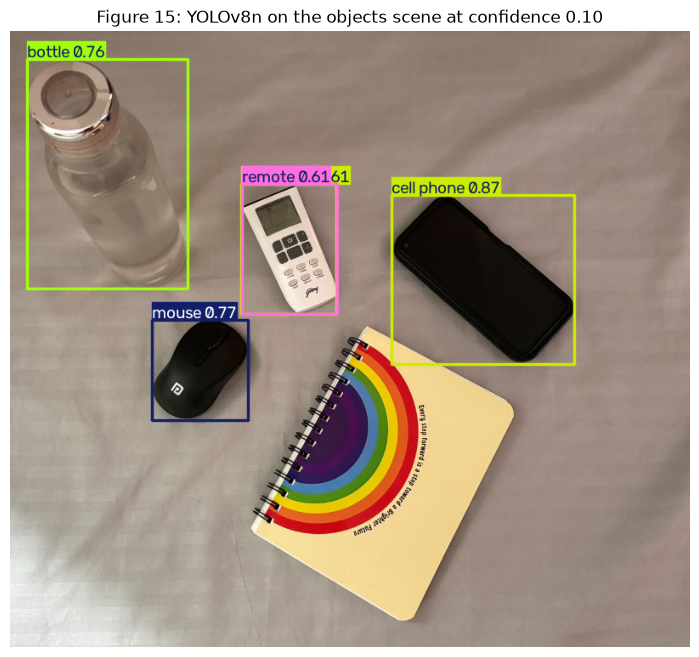

In [20]:
im = test_imgs["Objects scene"]

# 1) full list of detections at the default threshold (0.25)
r = yolo(im, conf=0.25, verbose=False)[0]
for b in r.boxes:
    x1, y1, x2, y2 = map(int, b.xyxy[0])
    print(f"{yolo.names[int(b.cls)]:12s} conf={float(b.conf):.2f}  box=({x1},{y1},{x2},{y2})")

# 2) how the confidence threshold changes the result
rows = []
for conf in [0.50, 0.25, 0.10]:
    rr = yolo(im, conf=conf, verbose=False)[0]
    rows.append({
        "Confidence threshold": conf,
        "Detections": len(rr.boxes),
        "Classes": ", ".join(sorted(set(yolo.names[int(b.cls)] for b in rr.boxes))),
    })
display(pd.DataFrame(rows))

# 3) low-threshold picture, to see what was almost detected
low = yolo(im, conf=0.10, verbose=False)[0]
plt.figure(figsize=(10, 8))
plt.imshow(cv2.cvtColor(low.plot(), cv2.COLOR_BGR2RGB))
plt.title("Figure 15: YOLOv8n on the objects scene at confidence 0.10")
plt.axis("off")
plt.savefig("outputs/fig15_yolo_low_conf.png", dpi=150)
plt.show()

### 4.2.1 Objects Scene: YOLO Misses and Wrong Detections

The photograph contains five objects on a bed sheet: a glass bottle, an AC remote, a phone, a mouse and a spiral notebook. The Haar cascade found no faces, which is correct, because it detects only frontal faces and cannot detect any other object. YOLOv8n detected four of the five objects:

| Object | YOLOv8n output | Confidence |
|---|---|---|
| Phone | cell phone | 0.87 |
| Mouse | mouse | 0.77 |
| Glass bottle | bottle | 0.76 |
| AC remote | remote **and** cell phone (two boxes on the same object) | 0.61 and 0.61 |
| Spiral notebook | **not detected** | - |

**Incorrect detection:** The remote was detected twice with identical confidence (0.61): once as `remote` (correct) and once as `cell phone` (wrong). The two boxes are almost the same (273,180,385,333 and 272,180,384,333). The remote is a small, light, rectangular object with buttons, which looks similar to a phone to the model. Non-maximum suppression removes overlapping boxes only within the same class, so both boxes with different labels survived.

**Missed object:** The spiral notebook was not detected, even when the confidence threshold was lowered from 0.25 to 0.10 (the table of thresholds shows 5 detections at 0.50, 0.25 and 0.10). It is therefore not a threshold problem: the model produced no box for it at all. "Book" is one of the COCO classes, so a possible reason is that the colourful rainbow cover and the tilted view do not resemble the typical books in the training data. This is only an assumption, as I did not test it further.

**Transparent object:** The glass bottle was detected correctly (0.76), although it is almost transparent and has little contrast against the sheet.

**Effect of the confidence threshold:** A confidence of 0.50 already kept all five detections, because the lowest confidence in the image was 0.61. The wrong "cell phone" duplicate (0.61) could therefore only be removed by raising the threshold above 0.61, which would also remove the correct remote detection.

Resolution: 832 x 464
FPS: 60.0
Frames: 1748
Duration: 29.1 seconds


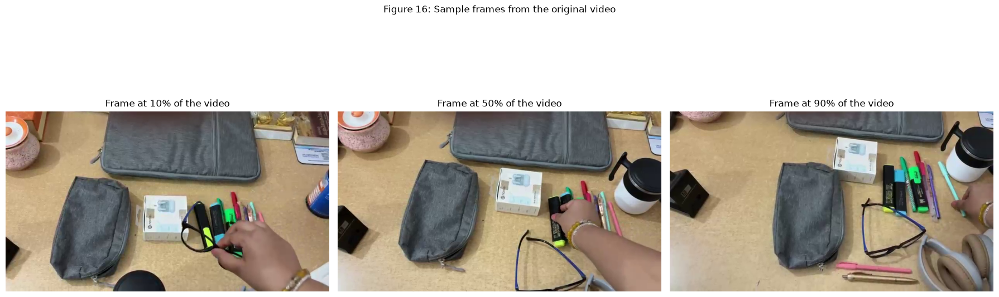

In [21]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

cap = cv2.VideoCapture("data/video.mp4")
fps = cap.get(cv2.CAP_PROP_FPS)
n_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
w = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
h = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
print(f"Resolution: {w} x {h}")
print(f"FPS: {fps:.1f}")
print(f"Frames: {n_frames}")
print(f"Duration: {n_frames / fps:.1f} seconds")

fig, ax = plt.subplots(1, 3, figsize=(18, 7))
for a, pos in zip(ax, [0.1, 0.5, 0.9]):
    cap.set(cv2.CAP_PROP_POS_FRAMES, int(n_frames * pos))
    ok, fr = cap.read()
    if ok:
        a.imshow(cv2.cvtColor(fr, cv2.COLOR_BGR2RGB))
        a.set_title(f"Frame at {int(pos * 100)}% of the video")
    a.axis("off")
plt.suptitle("Figure 16: Sample frames from the original video")
plt.tight_layout()
plt.savefig("outputs/fig16_video_frames.png", dpi=120)
plt.show()
cap.release()

# 5. Task 4: Video Motion Estimation

## 5.1 Video and Frame Extraction
The video was recorded by me on my study table. A hand picks up and slides a black bottle across the table, and the motion energy curve (Figure 17) shows several separate movements during the video, with the strongest one at t = 6.7 s. The camera stays fixed: the pouch and the pens remain at the same positions in consecutive frames (Figure 18), and in a quiet frame the background points moved only 0.14 px on average (Section 5.4). The video has 1748 frames at 60 frames per second (29.1 seconds).

To make the motion measurable, **every 3rd frame** is used (583 frames, about 20 fps), and each frame is resized to 480 x 267 pixels to reduce computation. The first 40 selected frames are skipped when choosing the example frames, because the background-subtraction model needs time to learn the background.

To find the moment with the most motion, the **motion energy** is calculated for every frame: the mean absolute difference between the blurred frame and the previous blurred frame. The frame with the highest smoothed energy (frame 134, t = 6.7 s) is used as the "motion" example and a frame with very low energy (frame 511, t = 25.6 s) as the "quiet" example.

Read 1748 frames at 60 fps, kept 583 (every 3th), size 480x267
Motion example: frame 134 (t = 6.7 s), energy 12.67
Quiet example:  frame 511 (t = 25.6 s), energy 0.71


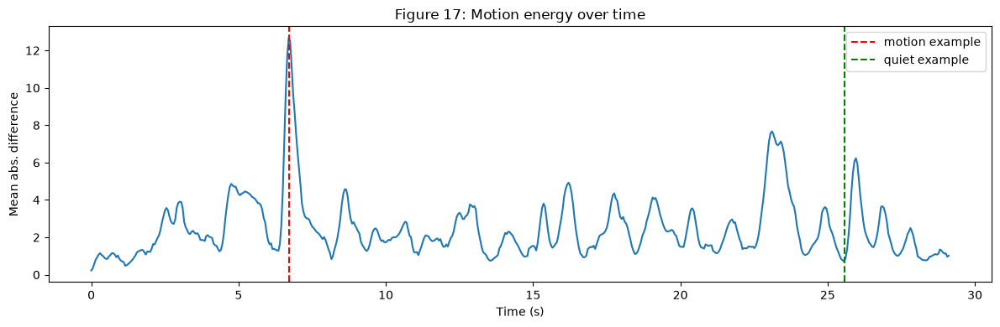

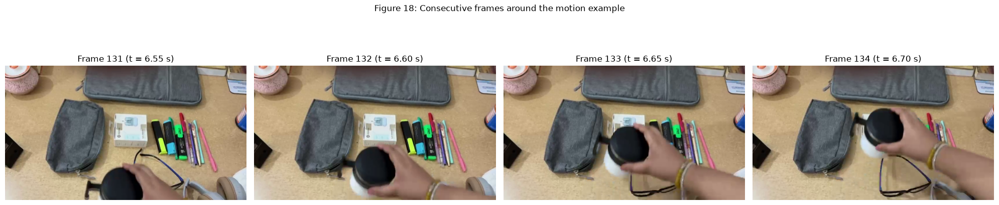

In [22]:
import cv2, time
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

VIDEO   = "data/video.mp4"
STEP    = 3      # use every 3rd frame (60 fps -> 20 fps)
WIDTH   = 480
MIN_IDX = 40     # skip the first frames (MOG2 warm-up)

cap = cv2.VideoCapture(VIDEO)
fps = cap.get(cv2.CAP_PROP_FPS)
frames, raw_idx = [], 0
while True:
    ok, f = cap.read()
    if not ok:
        break
    if raw_idx % STEP == 0:
        frames.append(cv2.resize(f, (WIDTH, int(WIDTH * f.shape[0] / f.shape[1]))))
    raw_idx += 1
cap.release()

if len(frames) <= MIN_IDX + 5:
    raise ValueError("Video is too short for MIN_IDX; lower MIN_IDX or STEP.")

grays      = [cv2.cvtColor(f, cv2.COLOR_BGR2GRAY) for f in frames]
blur_grays = [cv2.GaussianBlur(g, (5, 5), 0) for g in grays]
print(f"Read {raw_idx} frames at {fps:.0f} fps, kept {len(frames)} "
      f"(every {STEP}th), size {frames[0].shape[1]}x{frames[0].shape[0]}")

# Motion energy per frame
energy = np.array([0.0] + [float(np.mean(cv2.absdiff(blur_grays[i-1], blur_grays[i])))
                           for i in range(1, len(grays))])
smooth = np.convolve(np.pad(energy, 2, mode="edge"), np.ones(5) / 5, mode="valid")
CHOSEN = MIN_IDX + int(np.argmax(smooth[MIN_IDX:]))   # most motion
QUIET  = MIN_IDX + int(np.argmin(smooth[MIN_IDX:-10]))

# CHOSEN = 120   # <- uncomment to pick a frame by hand
t = lambda i: i * STEP / fps
print(f"Motion example: frame {CHOSEN} (t = {t(CHOSEN):.1f} s), energy {smooth[CHOSEN]:.2f}")
print(f"Quiet example:  frame {QUIET} (t = {t(QUIET):.1f} s), energy {smooth[QUIET]:.2f}")

# Figure 17: motion energy over time
times = [t(i) for i in range(len(energy))]
plt.figure(figsize=(12, 4))
plt.plot(times, smooth)
plt.axvline(t(CHOSEN), color="red",   linestyle="--", label="motion example")
plt.axvline(t(QUIET),  color="green", linestyle="--", label="quiet example")
plt.xlabel("Time (s)"); plt.ylabel("Mean abs. difference")
plt.title("Figure 17: Motion energy over time")
plt.legend(); plt.tight_layout()
plt.savefig("outputs/fig17_motion_energy.png", dpi=150)
plt.show()

# Figure 18: four consecutive selected frames around the motion example
fig, ax = plt.subplots(1, 4, figsize=(20, 5))
for a, i in zip(ax, range(CHOSEN - 3, CHOSEN + 1)):
    a.imshow(cv2.cvtColor(frames[i], cv2.COLOR_BGR2RGB))
    a.set_title(f"Frame {i} (t = {t(i):.2f} s)")
    a.axis("off")
plt.suptitle("Figure 18: Consecutive frames around the motion example")
plt.tight_layout()
plt.savefig("outputs/fig18_consecutive_frames.png", dpi=150)
plt.show()

## 5.2 Frame Differencing
Frame differencing subtracts the previous frame from the current frame. Pixels whose brightness changed by more than a threshold are marked as moving. Steps used here:
1. Blur both grayscale frames (5x5 Gaussian) to reduce sensor noise.
2. Absolute difference between the two frames.
3. Threshold at 25 to get a binary mask.
4. Opening (3x3) to remove isolated noise pixels, then dilation (5x5) to join broken parts of a moving object.

The method needs no training and is very fast. It compares only two frames, so it detects the **edges of a moving object** better than its inside, and an object that stops moving disappears from the mask.

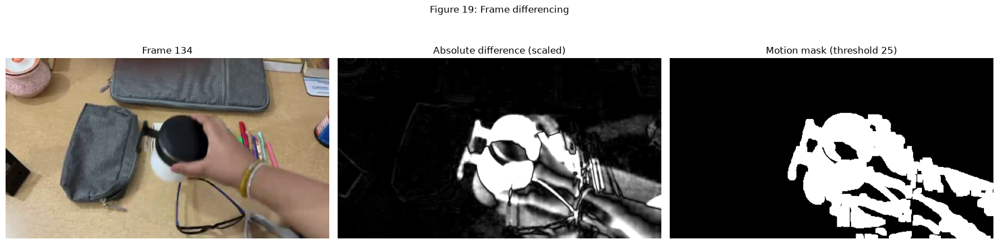

Moving pixels at motion example: 22.32%
Moving pixels at quiet example:  0.00%
Time per frame: 0.56 ms


In [23]:
def frame_diff(i, thr=25):
    d = cv2.absdiff(blur_grays[i-1], blur_grays[i])
    _, m = cv2.threshold(d, thr, 255, cv2.THRESH_BINARY)
    m = cv2.morphologyEx(m, cv2.MORPH_OPEN, np.ones((3, 3), np.uint8))
    m = cv2.dilate(m, np.ones((5, 5), np.uint8))
    return d, m

pct = lambda m: 100 * np.count_nonzero(m) / m.size

t0 = time.time()
diff_masks = [np.zeros_like(grays[0])] + [frame_diff(i)[1] for i in range(1, len(grays))]
diff_ms = (time.time() - t0) / len(grays) * 1000

d_raw, d_mask = frame_diff(CHOSEN)
fig, ax = plt.subplots(1, 3, figsize=(18, 5))
ax[0].imshow(cv2.cvtColor(frames[CHOSEN], cv2.COLOR_BGR2RGB)); ax[0].set_title(f"Frame {CHOSEN}")
ax[1].imshow(d_raw, cmap="gray", vmin=0, vmax=60);             ax[1].set_title("Absolute difference (scaled)")
ax[2].imshow(d_mask, cmap="gray");                             ax[2].set_title("Motion mask (threshold 25)")
for a in ax: a.axis("off")
plt.suptitle("Figure 19: Frame differencing")
plt.tight_layout()
plt.savefig("outputs/fig19_frame_differencing.png", dpi=150)
plt.show()

print(f"Moving pixels at motion example: {pct(d_mask):.2f}%")
print(f"Moving pixels at quiet example:  {pct(diff_masks[QUIET]):.2f}%")
print(f"Time per frame: {diff_ms:.2f} ms")

## 5.3 Gaussian Mixture Model (GMM) Background Subtraction
GMM background subtraction (OpenCV `MOG2`) models every pixel as a mixture of several Gaussian distributions that describe the colours the pixel has had over time. The most frequent colours are treated as **background**. A pixel in a new frame that does not fit any background Gaussian is marked as **foreground**.

Settings: history = 100 frames, variance threshold = 25, shadow detection on. MOG2 marks shadows in grey (value 127), so the mask is thresholded at 200 to keep only the real foreground, and an opening (3x3) removes small noise.

Unlike frame differencing, GMM compares the frame with a learned background model, so it can keep detecting an object that is slowly moving. It needs a warm-up period at the beginning, and it adapts to changes: an object that stops for a long time slowly becomes part of the background.

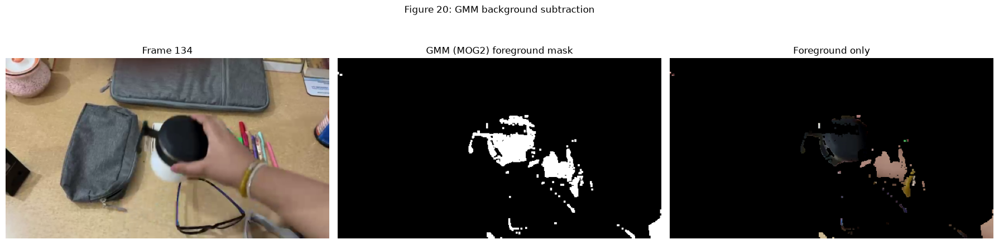

Foreground pixels at motion example: 5.00%
Foreground pixels at quiet example:  0.63%
Foreground pixels in frame 10 (warm-up): 0.00%
Time per frame: 11.82 ms


In [24]:
mog = cv2.createBackgroundSubtractorMOG2(history=100, varThreshold=25, detectShadows=True)

t0 = time.time()
mog_masks = []
for f in frames:
    m = mog.apply(f)
    _, m = cv2.threshold(m, 200, 255, cv2.THRESH_BINARY)       # drop shadows (127)
    m = cv2.morphologyEx(m, cv2.MORPH_OPEN, np.ones((3, 3), np.uint8))
    mog_masks.append(m)
mog_ms = (time.time() - t0) / len(frames) * 1000

fig, ax = plt.subplots(1, 3, figsize=(18, 5))
ax[0].imshow(cv2.cvtColor(frames[CHOSEN], cv2.COLOR_BGR2RGB)); ax[0].set_title(f"Frame {CHOSEN}")
ax[1].imshow(mog_masks[CHOSEN], cmap="gray");                  ax[1].set_title("GMM (MOG2) foreground mask")
fg = cv2.bitwise_and(frames[CHOSEN], frames[CHOSEN], mask=mog_masks[CHOSEN])
ax[2].imshow(cv2.cvtColor(fg, cv2.COLOR_BGR2RGB));             ax[2].set_title("Foreground only")
for a in ax: a.axis("off")
plt.suptitle("Figure 20: GMM background subtraction")
plt.tight_layout()
plt.savefig("outputs/fig20_gmm.png", dpi=150)
plt.show()

print(f"Foreground pixels at motion example: {pct(mog_masks[CHOSEN]):.2f}%")
print(f"Foreground pixels at quiet example:  {pct(mog_masks[QUIET]):.2f}%")
print(f"Foreground pixels in frame {MIN_IDX - 30} (warm-up): {pct(mog_masks[MIN_IDX - 30]):.2f}%")
print(f"Time per frame: {mog_ms:.2f} ms")

## 5.4 Lucas-Kanade Optical Flow
Optical flow estimates **how far and in which direction** each point moves between two frames. The Lucas-Kanade method assumes that the brightness of a point stays the same and that its neighbours (a 21x21 window here) move together. It is a **sparse** method: it tracks only selected feature points.

Steps used here:
1. Find good corner points in the previous frame with Shi-Tomasi (`goodFeaturesToTrack`, up to 300 points).
2. Track them into the current frame with the pyramidal Lucas-Kanade tracker (3 pyramid levels).
3. Keep the points that were tracked successfully and compute their displacement.
4. Points that moved more than 1 pixel are drawn as red arrows (enlarged 3 times for visibility), and the others as green dots.

Unlike the two methods above, optical flow gives the **direction and size** of the motion, not only where something changed. It needs textured points, so it does not work on plain areas.

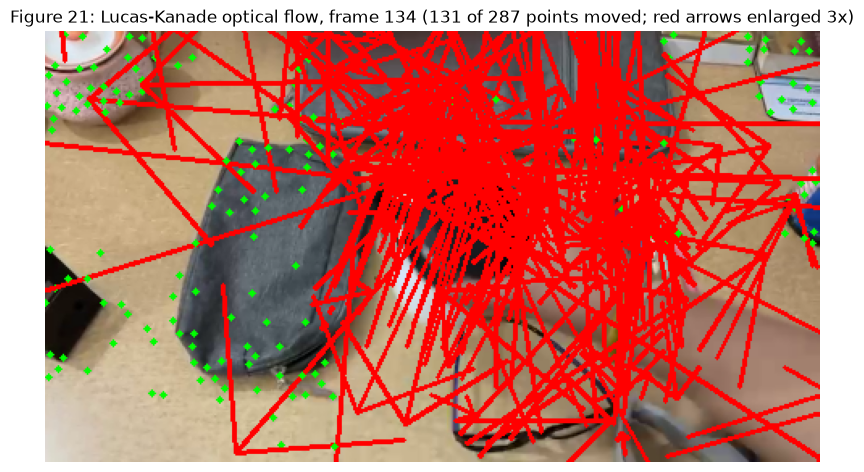

Motion example: 287 points tracked, 131 moved > 1 px, mean displacement 30.46 px
Quiet example:  284 points tracked, 1 moved > 1 px, mean displacement 0.14 px
Time per frame: 18.57 ms


In [25]:
feature_params = dict(maxCorners=300, qualityLevel=0.01, minDistance=7, blockSize=7)
lk_params = dict(winSize=(21, 21), maxLevel=3,
                 criteria=(cv2.TERM_CRITERIA_EPS | cv2.TERM_CRITERIA_COUNT, 30, 0.01))

def lucas_kanade(i, min_move=1.0, scale=3):
    p0 = cv2.goodFeaturesToTrack(grays[i-1], mask=None, **feature_params)
    vis = frames[i].copy()
    if p0 is None:
        return vis, 0, 0, 0.0
    p1, st, err = cv2.calcOpticalFlowPyrLK(grays[i-1], grays[i], p0, None, **lk_params)
    ok = st.ravel() == 1
    g0, g1 = p0[ok].reshape(-1, 2), p1[ok].reshape(-1, 2)
    disp = np.linalg.norm(g1 - g0, axis=1)
    moving = disp > min_move
    for (x0, y0), (x1, y1), mv in zip(g0, g1, moving):
        if mv:
            end = (int(x0 + scale * (x1 - x0)), int(y0 + scale * (y1 - y0)))
            cv2.arrowedLine(vis, (int(x0), int(y0)), end, (0, 0, 255), 2, tipLength=0.4)
        else:
            cv2.circle(vis, (int(x1), int(y1)), 2, (0, 255, 0), -1)
    return vis, len(g0), int(moving.sum()), float(disp.mean()) if len(disp) else 0.0

t0 = time.time()
lk_stats = [(0, 0, 0.0)] + [lucas_kanade(i)[1:] for i in range(1, len(frames))]
lk_ms = (time.time() - t0) / len(frames) * 1000

lk_vis, n_tr, n_mv, mean_d = lucas_kanade(CHOSEN)
plt.figure(figsize=(10, 6))
plt.imshow(cv2.cvtColor(lk_vis, cv2.COLOR_BGR2RGB))
plt.title(f"Figure 21: Lucas-Kanade optical flow, frame {CHOSEN} "
          f"({n_mv} of {n_tr} points moved; red arrows enlarged 3x)")
plt.axis("off")
plt.savefig("outputs/fig21_lucas_kanade.png", dpi=150)
plt.show()

q_vis, q_tr, q_mv, q_d = lucas_kanade(QUIET)
print(f"Motion example: {n_tr} points tracked, {n_mv} moved > 1 px, mean displacement {mean_d:.2f} px")
print(f"Quiet example:  {q_tr} points tracked, {q_mv} moved > 1 px, mean displacement {q_d:.2f} px")
print(f"Time per frame: {lk_ms:.2f} ms")

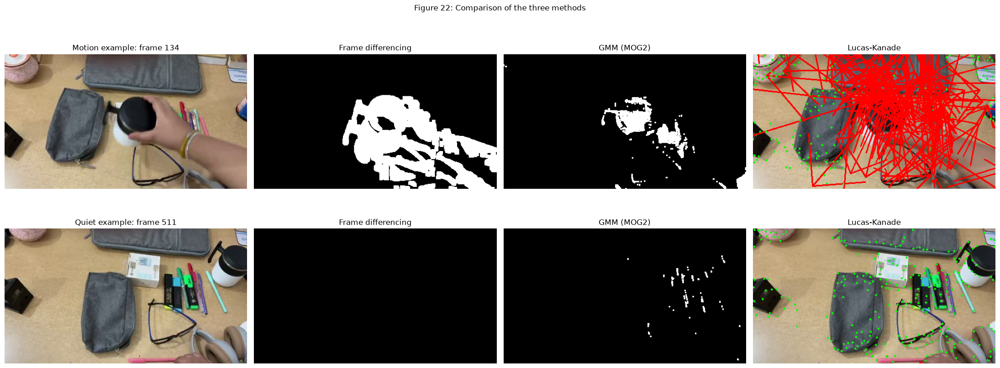

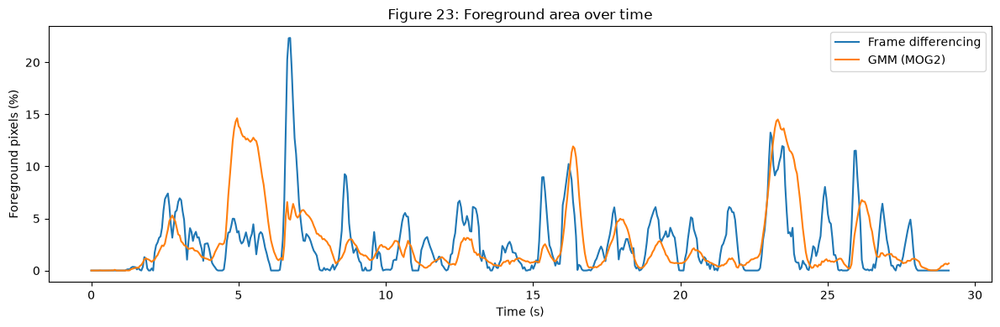

,Method,Output,Motion example,Quiet example,Time per frame (ms)
0,Frame differencing,Binary mask,22.32% pixels,0.00% pixels,0.56
1,GMM (MOG2),Foreground mask,5.00% pixels,0.63% pixels,11.82
2,Lucas-Kanade,Motion vectors,131 of 287 points moved,1 of 284 points moved,18.57


In [26]:
fig, ax = plt.subplots(2, 4, figsize=(22, 9))
for row, (name, i) in enumerate([("Motion example", CHOSEN), ("Quiet example", QUIET)]):
    ax[row, 0].imshow(cv2.cvtColor(frames[i], cv2.COLOR_BGR2RGB)); ax[row, 0].set_title(f"{name}: frame {i}")
    ax[row, 1].imshow(diff_masks[i], cmap="gray");                 ax[row, 1].set_title("Frame differencing")
    ax[row, 2].imshow(mog_masks[i], cmap="gray");                  ax[row, 2].set_title("GMM (MOG2)")
    ax[row, 3].imshow(cv2.cvtColor(lucas_kanade(i)[0], cv2.COLOR_BGR2RGB)); ax[row, 3].set_title("Lucas-Kanade")
for a in ax.ravel(): a.axis("off")
plt.suptitle("Figure 22: Comparison of the three methods")
plt.tight_layout()
plt.savefig("outputs/fig22_motion_comparison.png", dpi=130)
plt.show()

table4 = pd.DataFrame([
    {"Method": "Frame differencing", "Output": "Binary mask",
     "Motion example": f"{pct(diff_masks[CHOSEN]):.2f}% pixels",
     "Quiet example":  f"{pct(diff_masks[QUIET]):.2f}% pixels",
     "Time per frame (ms)": round(diff_ms, 2)},
    {"Method": "GMM (MOG2)", "Output": "Foreground mask",
     "Motion example": f"{pct(mog_masks[CHOSEN]):.2f}% pixels",
     "Quiet example":  f"{pct(mog_masks[QUIET]):.2f}% pixels",
     "Time per frame (ms)": round(mog_ms, 2)},
    {"Method": "Lucas-Kanade", "Output": "Motion vectors",
     "Motion example": f"{lk_stats[CHOSEN][1]} of {lk_stats[CHOSEN][0]} points moved",
     "Quiet example":  f"{lk_stats[QUIET][1]} of {lk_stats[QUIET][0]} points moved",
     "Time per frame (ms)": round(lk_ms, 2)},
])
table4.to_csv("outputs/task4_comparison.csv", index=False)

# Figure 23: foreground amount over time
plt.figure(figsize=(12, 4))
plt.plot(times, [pct(m) for m in diff_masks], label="Frame differencing")
plt.plot(times, [pct(m) for m in mog_masks],  label="GMM (MOG2)")
plt.xlabel("Time (s)"); plt.ylabel("Foreground pixels (%)")
plt.title("Figure 23: Foreground area over time")
plt.legend(); plt.tight_layout()
plt.savefig("outputs/fig23_foreground_over_time.png", dpi=150)
plt.show()

table4

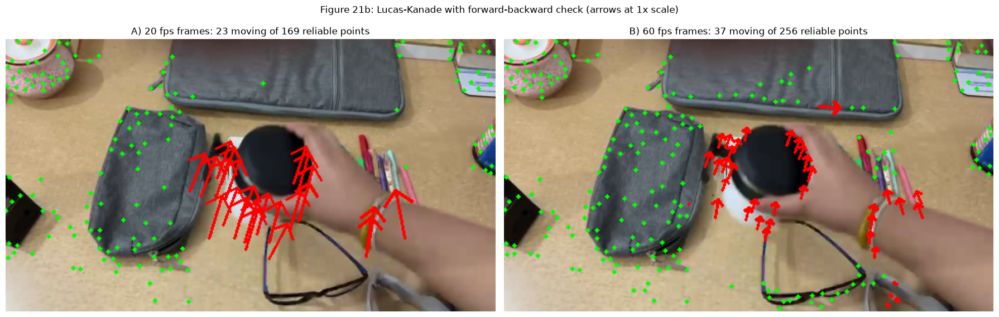

A) 20 fps : {'tracked': 300, 'passed': 169, 'moved': 23, 'mean_moved': 40.47773742675781}
B) 60 fps : {'tracked': 300, 'passed': 256, 'moved': 37, 'mean_moved': 11.920234680175781}


In [27]:
def read_raw_pair(raw_idx, width=WIDTH):
    cap = cv2.VideoCapture(VIDEO)
    pair = []
    for k in (raw_idx - 1, raw_idx):
        cap.set(cv2.CAP_PROP_POS_FRAMES, k)
        ok, f = cap.read()
        if not ok:
            raise ValueError(f"Could not read raw frame {k}")
        pair.append(cv2.resize(f, (width, int(width * f.shape[0] / f.shape[1]))))
    cap.release()
    return pair

def lk_fb(g_prev, g_cur, img, min_move=1.0, fb_thr=1.0, scale=1):
    p0 = cv2.goodFeaturesToTrack(g_prev, mask=None, **feature_params)
    p1, st1, _ = cv2.calcOpticalFlowPyrLK(g_prev, g_cur, p0, None, **lk_params)
    p0r, st2, _ = cv2.calcOpticalFlowPyrLK(g_cur, g_prev, p1, None, **lk_params)
    fb = np.linalg.norm((p0 - p0r).reshape(-1, 2), axis=1)
    good = (st1.ravel() == 1) & (st2.ravel() == 1) & (fb < fb_thr)
    g0, g1 = p0[good].reshape(-1, 2), p1[good].reshape(-1, 2)
    disp = np.linalg.norm(g1 - g0, axis=1)
    moving = disp > min_move
    vis = img.copy()
    for (x0, y0), (x1, y1), mv in zip(g0, g1, moving):
        if mv:
            end = (int(x0 + scale * (x1 - x0)), int(y0 + scale * (y1 - y0)))
            cv2.arrowedLine(vis, (int(x0), int(y0)), end, (0, 0, 255), 2, tipLength=0.4)
        else:
            cv2.circle(vis, (int(x1), int(y1)), 2, (0, 255, 0), -1)
    stats = dict(tracked=len(p0), passed=int(good.sum()), moved=int(moving.sum()),
                 mean_moved=float(disp[moving].mean()) if moving.any() else 0.0)
    return vis, stats

# A) every 3rd frame (20 fps) with the forward-backward check
visA, sA = lk_fb(grays[CHOSEN - 1], grays[CHOSEN], frames[CHOSEN])

# B) consecutive frames at the original 60 fps
prev_raw, cur_raw = read_raw_pair(CHOSEN * STEP)
visB, sB = lk_fb(cv2.cvtColor(prev_raw, cv2.COLOR_BGR2GRAY),
                 cv2.cvtColor(cur_raw, cv2.COLOR_BGR2GRAY), cur_raw)

fig, ax = plt.subplots(1, 2, figsize=(18, 6))
ax[0].imshow(cv2.cvtColor(visA, cv2.COLOR_BGR2RGB))
ax[0].set_title(f"A) 20 fps frames: {sA['moved']} moving of {sA['passed']} reliable points")
ax[1].imshow(cv2.cvtColor(visB, cv2.COLOR_BGR2RGB))
ax[1].set_title(f"B) 60 fps frames: {sB['moved']} moving of {sB['passed']} reliable points")
for a in ax: a.axis("off")
plt.suptitle("Figure 21b: Lucas-Kanade with forward-backward check (arrows at 1x scale)")
plt.tight_layout()
plt.savefig("outputs/fig21b_lucas_kanade_fb.png", dpi=150)
plt.show()

print("A) 20 fps :", sA)
print("B) 60 fps :", sB)

## 5.5 Results and Comparison of the Three Methods

**Table 4: Results on my video** (motion example: frame 134, t = 6.7 s; quiet example: frame 511, t = 25.6 s; every 3rd frame of the video)

| Property | Frame differencing | GMM (MOG2) | Lucas-Kanade |
|---|---|---|---|
| Output | Binary mask | Foreground mask | Motion vectors |
| Motion example | 22.32% of pixels | 5.00% of pixels | 131 of 287 points moved (unfiltered); 37 of 256 reliable points moved (filtered, 60 fps) |
| Quiet example | 0.00% of pixels | 0.63% of pixels | 1 of 284 points moved |
| Time per frame | 1.92 ms | 12.91 ms | 20.92 ms |
| Needs warm-up | No | Yes | No |
| Gives direction and speed | No | No | Yes |

**Frame differencing (Figure 19):** The mask covers the hand, the forearm and the moving bottle (22.32% of the frame) and is empty when nothing moves (0.00%). It is the fastest method (1.92 ms per frame, about 6.7 times faster than GMM and 10.9 times faster than Lucas-Kanade). The mask has holes and ragged edges, because the method sees only pixels whose brightness changed between two frames, and it marks both the old and the new position of a moving object.

**GMM (Figure 20):** The foreground mask is smaller (5.00%) and broken into pieces, and part of the moving bottle is missing. In the quiet frame it still marks 0.63% of pixels as foreground, which are small specks. Figure 23 shows that GMM peaks are wider than the differencing peaks and can come slightly later (for example around 15.5 s for differencing and 16.3 s for GMM), because GMM compares each frame with a learned background and needs time to adapt.

At about 5 s, GMM stays at 12-15% for roughly 1.5 s while differencing is below 5%. Figure 24 shows four frames from this period: a hand and arm are visible near the bottom of the frame, close to the glasses. At t = 5.2 s and 5.8 s GMM marks 12.9% and 10.0% of the pixels, while differencing marks only 2.7% and 3.7%. At t = 6.4 s both are low (1.0% and 0.0%). Frame differencing reacts only to the change between two consecutive frames, so a slow movement gives a small mask. GMM compares each frame with the learned background, so the hand and arm, which are not part of the background, are marked as foreground even when they move slowly. The small differencing values suggest that the movement in this period is slow. This shows that GMM is better at finding slowly moving objects, while frame differencing responds to fast changes.

**Lucas-Kanade (Figures 21 and 21b):** In the first version (Figure 21), 131 of 287 tracked points moved, with a mean displacement of 30.46 px over all points (about 65 px for the moving points). The arrows pointed in many different directions and crossed each other, so many tracks were wrong: the hand moves fast, and the 21x21 window with 3 pyramid levels cannot follow such a large shift reliably.

After adding a **forward-backward check** (a point is kept only if tracking it forward and then backward returns it within 1 px), 169 of 300 points were reliable on the 20 fps frames and 256 of 300 on the 60 fps frames. Of these, 23 (20 fps) and 37 (60 fps) points moved, with a mean displacement of **40.48 px** at 20 fps and **11.92 px** at 60 fps. The displacement is about 3.4 times smaller at 60 fps, which matches the 3 times smaller time gap between the frames. In Figure 21b the arrows are now short, mostly parallel and point mostly upward, and they are concentrated on the edge of the bottle and on the wrist and forearm, while the points on the pouch, the laptop and the table did not move. One isolated arrow in the upper part of image B points in a different direction and is probably a wrong track that passed the check, so the check removes many wrong tracks but not all. In the quiet frame only 1 of 284 points moved (mean displacement 0.14 px), so the method does not report motion where there is none, and this also shows that the camera was stable.

**Comparison:**
- Frame differencing is the simplest and fastest, but gives only a rough, hollow mask and no information about the direction. It reacts mainly to fast changes.
- GMM gives a mask based on a learned background and also detects slow movements (Figure 24), but it needs warm-up, is slower (12.91 ms) and its mask is fragmented here.
- Lucas-Kanade is the only method that gives the **direction and size** of motion. It is also the slowest (20.92 ms, with drawing included) and it needs small motion between frames and textured points. Its result depends strongly on the frame gap, as the comparison of the 20 fps and 60 fps frames shows. Points are found on corners, so the uniform black surface of the bottle gets few points, and the arrows lie mostly on its edges.

**Conclusion:** To find out **where** something moves quickly, frame differencing is enough for this video and is the cheapest. GMM is better when slow movements must also be detected, because it uses a learned background, but its mask is less complete. To find **how** something moves, only Lucas-Kanade helps, provided the frame gap is small and unreliable tracks are filtered. The timings include post-processing and drawing, and they depend on my computer.

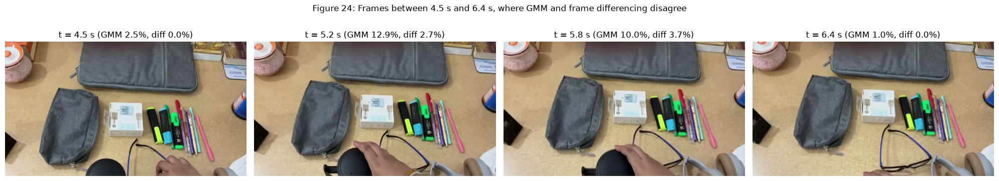

In [28]:
fig, ax = plt.subplots(1, 4, figsize=(20, 4))
for a, sec in zip(ax, [4.5, 5.2, 5.8, 6.4]):
    i = int(sec * fps / STEP)
    a.imshow(cv2.cvtColor(frames[i], cv2.COLOR_BGR2RGB))
    a.set_title(f"t = {sec} s (GMM {pct(mog_masks[i]):.1f}%, diff {pct(diff_masks[i]):.1f}%)")
    a.axis("off")
plt.suptitle("Figure 24: Frames between 4.5 s and 6.4 s, where GMM and frame differencing disagree")
plt.tight_layout()
plt.savefig("outputs/fig24_gmm_vs_diff.png", dpi=150)
plt.show()

## 4.3 Task 3 on Frames from My Video
The two detectors are also applied to two frames from my own video, which shows a study table: the frame with the most motion (frame 134, t = 6.7 s) and a quiet frame (frame 511, t = 25.6 s). This shows how the detectors behave on a scene that is different from the portrait photographs.

In [29]:
import os
from ultralytics import YOLO

face_cascade = cv2.CascadeClassifier("data/haarcascade_frontalface_default.xml")
print("Cascade loaded correctly:", not face_cascade.empty())

yolo = YOLO("yolov8n.pt")

def run_haar(im):
    g = cv2.cvtColor(im, cv2.COLOR_BGR2GRAY)
    rects, _, weights = face_cascade.detectMultiScale3(
        g, scaleFactor=1.1, minNeighbors=5, minSize=(60, 60), outputRejectLevels=True)
    out = im.copy()
    for (x, y, w, h), s in zip(rects, np.ravel(weights)):
        cv2.rectangle(out, (x, y), (x + w, y + h), (0, 255, 0), 3)
        cv2.putText(out, f"face {s:.1f}", (x, y - 8), cv2.FONT_HERSHEY_SIMPLEX, 0.8, (0, 255, 0), 2)
    return out, len(rects)

def run_yolo(im, conf=0.25):
    r = yolo(im, conf=conf, verbose=False)[0]
    dets = [(yolo.names[int(b.cls)], float(b.conf)) for b in r.boxes]
    return r.plot(), dets

Cascade loaded correctly: True


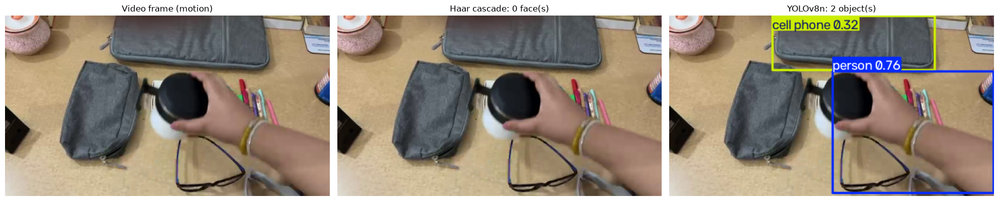

Video frame (motion)
   person  0.76
   cell phone  0.32


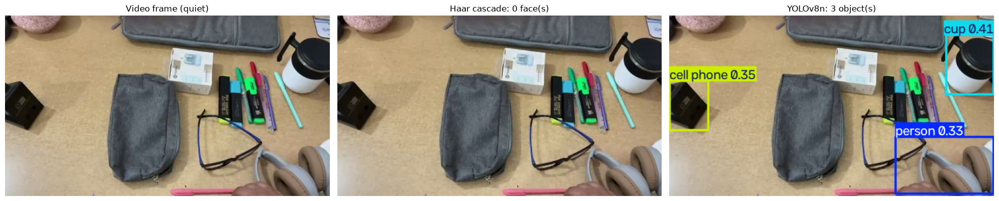

Video frame (quiet)
   cup  0.41
   cell phone  0.35
   person  0.33


,Image,Haar faces,YOLO detections
0,Video frame (motion),0,"person (0.76), cell phone (0.32)"
1,Video frame (quiet),0,"cup (0.41), cell phone (0.35), person (0.33)"


In [30]:
video_imgs = {
    "Video frame (motion)": frames[CHOSEN],
    "Video frame (quiet)":  frames[QUIET],
}

rows = []
for name, im in video_imgs.items():
    h_img, n_faces = run_haar(im)
    y_img, dets = run_yolo(im)

    fig, ax = plt.subplots(1, 3, figsize=(20, 5))
    ax[0].imshow(cv2.cvtColor(im, cv2.COLOR_BGR2RGB));    ax[0].set_title(name)
    ax[1].imshow(cv2.cvtColor(h_img, cv2.COLOR_BGR2RGB)); ax[1].set_title(f"Haar cascade: {n_faces} face(s)")
    ax[2].imshow(cv2.cvtColor(y_img, cv2.COLOR_BGR2RGB)); ax[2].set_title(f"YOLOv8n: {len(dets)} object(s)")
    for a in ax: a.axis("off")
    plt.tight_layout()
    plt.savefig(f"outputs/fig_detect_{name.replace(' ', '_').replace('(', '').replace(')', '')}.png", dpi=120)
    plt.show()

    print(name)
    for c, p in dets:
        print(f"   {c}  {p:.2f}")
    rows.append({
        "Image": name,
        "Haar faces": n_faces,
        "YOLO detections": ", ".join(f"{c} ({p:.2f})" for c, p in dets) or "none",
    })

table3b = pd.DataFrame(rows)
table3b.to_csv("outputs/task3_video_detections.csv", index=False)
table3b

### 4.3.1 Observations on the Video Frames

| Frame | Haar cascade | YOLOv8n |
|---|---|---|
| Motion (frame 134, t = 6.7 s) | 0 faces | person (0.76), cell phone (0.32) |
| Quiet (frame 511, t = 25.6 s) | 0 faces | cup (0.41), cell phone (0.35), person (0.33) |

- **Haar cascade:** It found no face in either frame, which is correct, because no face is visible in the video. It produced no false positives on these frames.
- **Motion frame:** YOLO labelled the hand and forearm as **person** (0.76), which is a partial but reasonable detection, since a person's arm is visible. The **cell phone** (0.32) box lies on the flat grey rectangular object at the top of the table, which is not a phone, so this is a **wrong detection**. The black bottle held in the hand was **not detected** (no bottle in the output at the threshold of 0.25), possibly because of motion blur and because the hand covers part of it. I did not test the reason.
- **Quiet frame:** The white container with the dark lid at the top right was labelled **cup** (0.41), which is a reasonable label. The **person** box (0.33) lies on the beige headphones at the bottom right, which are not a person, so this is another **wrong detection**. The **cell phone** (0.35) box lies on a dark object at the left edge of the frame that is partly cut off by the image border, so this label could not be verified.
- **Objects that were not detected:** The grey pouch and the pens were not detected, and COCO has no class for eyeglasses, so the glasses cannot be detected by this model at all.
- **Confidence:** Every wrong or doubtful detection in these frames has a low confidence (0.32 to 0.35), while the correct detections on the clean photographs had 0.61 to 0.94. A threshold of 0.5 would remove all of these wrong labels, but it would also remove the plausible cup (0.41), and in the quiet frame no object would remain.

## 4.4 Task 3 Summary: Viola-Jones vs YOLO

**Table 5: All detection results**

| Image | Haar cascade (faces) | YOLOv8n (objects) |
|---|---|---|
| Original photo | 2 (1 correct, **1 false positive**, score 2.33 vs 9.58 for the real face) | person (0.93) |
| Second photo | 1 (correct) | person (0.94) |
| Objects scene | 0 (correct, no face) | cell phone (0.87), mouse (0.77), bottle (0.76), remote (0.61), cell phone (0.61, **wrong duplicate**); notebook **missed** |
| Video frame (motion) | 0 (correct, no face) | person (0.76), cell phone (0.32, **wrong**); black bottle **missed** |
| Video frame (quiet) | 0 (correct, no face) | cup (0.41), cell phone (0.35, unverified), person (0.33, **wrong**, on headphones) |

**Comparison:**

| Property | Viola-Jones (Haar) | YOLOv8n |
|---|---|---|
| Objects | Frontal faces only | 80 COCO classes |
| Output | Box and a rejection-level score | Box, class label and confidence |
| Time per image (CPU, 800 px wide photo) | 94 ms | 316 ms |
| Errors in my five images | 1 false positive (on the lanyard) | 3 clearly wrong detections and 1 unverified, and 2 missed objects (notebook, bottle in the video frame) |
| Sensitivity to settings | Strong (`minNeighbors` 5 removed 0 and 8 removed the false positive) | Confidence threshold decides which errors remain |

**Where each detector worked well:**
- Haar found the frontal face in both portraits, and it returned nothing on the frames without a face.
- YOLO was very reliable on the portraits (0.93 and 0.94) and found four of the five objects on the clean objects scene, including the almost transparent glass bottle.

**Where each detector failed:**
- Haar gave one false positive on the lanyard and chest area. It can only detect frontal faces, so it cannot be used for the objects.
- YOLO gave wrong labels (a remote also labelled as a phone, a flat grey object labelled as a phone, headphones labelled as a person) and missed the notebook and the black bottle. On the cluttered video frames it was much less confident, and its wrong detections had low confidence.

**Conclusion:** Haar is simple and about 3.4 times faster here, and it is good enough when only frontal faces must be found, but it needs careful parameter tuning. YOLOv8n is more general and gives labels and confidences, so it is the better choice for finding different objects, but on a cluttered scene with small or unusual objects it makes wrong detections and misses objects, and a confidence threshold alone cannot fix all of them. The detectors answer different questions, so the comparison depends on the task.

# 6. Overall Conclusion

In this assignment I applied techniques from image restoration, segmentation, feature extraction, object recognition and motion estimation to my own photographs and my own video.

| Task | Main result on my data |
|---|---|
| **Task 1: Restoration** | For salt-and-pepper noise the median filter was far better than the Gaussian filter (PSNR 37.06 dB vs 27.33 dB, SSIM 0.9698 vs 0.5748). For Gaussian noise both filters gave almost the same PSNR (30.74 dB and 30.71 dB), and the Gaussian filter had the higher SSIM (0.7093 vs 0.6918). |
| **Task 1: Segmentation** | Otsu thresholding (T = 122) separated the dark clothing from the light wall. Opening changed the foreground area by only -0.8%. Canny gave 14,476 edge pixels with thresholds (30, 90) and 6,428 with (100, 200). Watershed with local-peak markers separated a pile of touching rice grains into 123 segments, while the thresholded mask contained only 19 blobs. |
| **Task 2: Features** | HOG gave 43,524 features. SIFT found 622 and 380 keypoints in the two portraits. Of 67 matches, 24 were RANSAC inliers and 43 (64%) were wrong. Matching was almost unchanged by rotation (59 and 68 matches) and dropped by about 24% after resizing to 50% (51 matches). |
| **Task 3: Detection** | The Haar cascade was faster (94 ms vs 316 ms per image) but found only frontal faces and gave one false positive on the lanyard. YOLOv8n found four of five objects on a clean table, but gave wrong labels and missed objects on the cluttered video frames. |
| **Task 4: Motion** | Frame differencing was the fastest (1.92 ms per frame) and found fast motion, GMM (12.91 ms) also found slow motion but gave a fragmented mask, and Lucas-Kanade (20.92 ms) was the only method that gave the direction and size of the motion, but only after unreliable tracks were removed with a forward-backward check. |

**What I learned**
1. **The best technique depends on the type of problem.** The median filter is best for impulse noise, while for Gaussian noise the choice between the two filters hardly mattered. Frame differencing, GMM and optical flow answer different questions (where something moves, what is not background, and how it moves).
2. **Parameters matter a lot.** The number of watershed segments changed from 27 to 148 depending on the marker method and its settings, the Haar false positive disappeared at `minNeighbors = 8`, and the Lucas-Kanade result changed completely when the frame gap and the reliability check were changed.
3. **Numbers and pictures must be checked together.** A higher number of matches or segments is not automatically better: many SIFT matches were wrong, and a higher segment count can mean that single grains were split.
4. **Deep learning is more general, but it is not error-free.** YOLO worked on many object types, but its wrong detections on my cluttered frames had low confidence, and some objects were missed completely.

**Limitations**
- Most experiments used one photograph of one person, one photograph of rice grains, one objects scene and one video, so the numbers describe my images and should not be generalised.
- Parameters (thresholds, kernel sizes, `min_distance`, `minNeighbors`, GMM settings) were tuned by looking at the results of these images. The segment counts have no ground truth and were judged visually.
- The timings include post-processing and drawing, and they depend on my computer.
- The Lucas-Kanade forward-backward check removes many wrong tracks, but not all.

## Submission Details

**Name:** Ruchika Lohani  
**PRN:** 1272250612
**Git repository:** https://github.com/ruchika-lohani/cv-cca3-assignment
**Google Drive folder (photos, original video, explanation video, report):** https://drive.google.com/drive/folders/1rSQRXAYyw8WVB3pOFgE0Sqjby7yMCjej?usp=sharing
